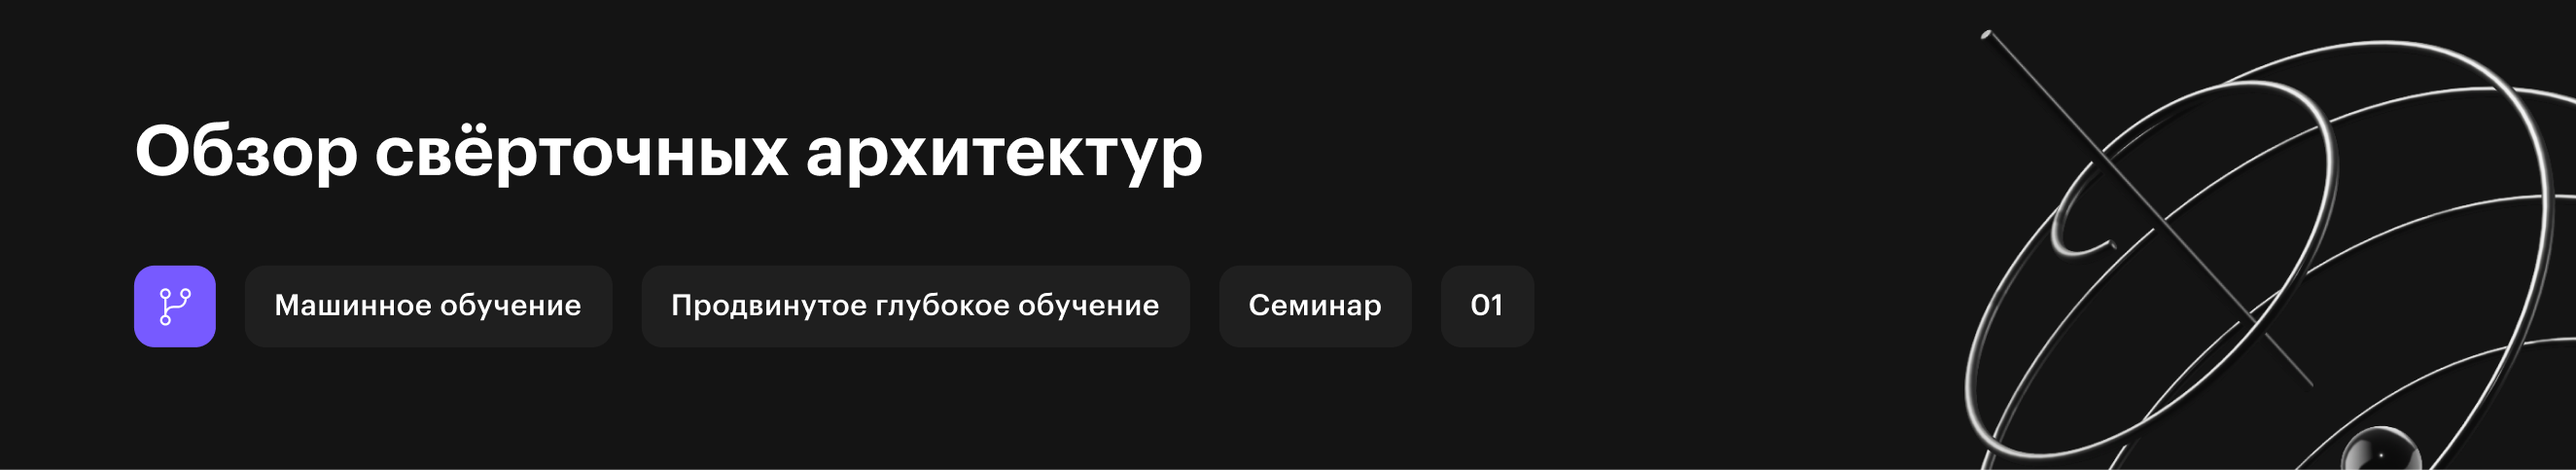

# Занятие 1. Обзор свёрточных архитектур

Сегодня мы совершим экскурс в разнообразные архитектуры `CNN`. Важность такого обзора обусловлена тем, что они не только могут использоваться непосредственно для решения задач компьютерного зрения, но и служат генераторами базовых признаков для более сложных задач, таких как отслеживание движения объектов, сегментации, обнаружения объектов или преобразование стилей.

Каждый раздел занятия соответствует значительной архитектуре `CNN`, которая в какой-то момент (или в настоящее время) была базовой моделью, на которой строились многие исследовательские проекты и коммерческие системы. Каждая из этих сетей в течение короткого времени была доминирующей архитектурой, а многие из них стали победителями или призёрами конкурса `ImageNet`, который с 2010 года служит барометром прогресса в области глубокого обучения в компьютерном зрении. Лишь недавно трансформеры начали вытеснять `CNN`, начиная с `Dosovitskiy et al.(2021)` и заканчивая трансформером `Swin (Liu et al., 2021)`.

Хотя идея глубоких нейронных сетей довольно проста (сложить вместе несколько слоёв), производительность может сильно различаться в зависимости от архитектуры и выбора гиперпараметров. Нейронные сети, описанные в этой главе, являются продуктом интуиции, нескольких математических открытий и множества проб и ошибок.

Модели на занятии представлены в хронологическом порядке — отчасти для того, чтобы передать ощущение истории, чтобы вы могли сформировать свои собственные представления о том, куда движется область, и, возможно, разработать свои собственные архитектуры. Например, пакетная нормализация (batch-normalization) и остаточные связи (residual connection) предложили две популярные идеи для обучения и проектирования глубоких моделей, и обе они впоследствии были применены и в архитектурах, выходящих за рамки компьютерного зрения.

Мы начинаем знакомство с `CNN` `AlexNet` `(Krizhevsky et al., 2012)`, первой крупномасштабной сети, которая победила обычные методы компьютерного зрения; сеть `VGG (Simonyan and Zisserman, 2014)`, которая использует ряд повторяющихся блоков элементов; сети в сети `(NiN)`, которая свёртывает целые нейронные сети по входу `(Lin et al., 2013)`; `GoogLeNet`, использующая сети с несколькими ветвями, где имеются свёртки разных размеров `(Szegedy et al., 2015)`; остаточная сеть `(ResNet) (He et al., 2016)`, которая остаётся одной из самых популярных готовых архитектур в компьютерном зрении; блоки `ResNeXt (Xie et al., 2017)` для более редких связей; и `DenseNet (Huang et al., 2017)` — обобщениe остаточной архитектуры.

В дальнейшем было разработано множество специальных оптимизаций для создания эффективных сетей, например сдвиг координат `(ShiftNet) (Wu et al., 2018)`. Кульминацией стал автоматический поиск эффективных архитектур, таких как `MobileNet v3 (Howard et al., 2019)`. Сюда же относится полуавтоматический поиск архитектуры сети `Radosavovic et al. (2020)`, который привёл к созданию `RegNetX/Y`.

Импортируем требуемые библиотеки.

In [ ]:
import torchvision.transforms as transforms
import plotly.graph_objects   as go
import plotly.express         as px
import numpy                  as np
import scipy                  as sp

import torch

from torch.nn             import functional as F
from torch                import nn

from torchsummary         import summary

/home/sergey/anaconda3/envs/work/lib/python3.8/site-packages/onnxscript/converter.py:823: FutureWarning: 'onnxscript.values.Op.param_schemas' is deprecated in version 0.1 and will be removed in the future. Please use '.op_signature' instead.
  param_schemas = callee.param_schemas()
/home/sergey/anaconda3/envs/work/lib/python3.8/site-packages/onnxscript/converter.py:823: FutureWarning: 'onnxscript.values.OnnxFunction.param_schemas' is deprecated in version 0.1 and will be removed in the future. Please use '.op_signature' instead.
  param_schemas = callee.param_schemas()


Общая функция, которую будем использовать для инициализации весов наших моделей.

In [ ]:
def init_cnn(module):
    """Initialize weights for CNNs.

    Defined in :numref:`sec_lenet`"""
    if type(module) == nn.Linear or type(module) == nn.Conv2d:
        nn.init.xavier_uniform_(module.weight)

## Свёрточная нейронная сеть (LeNet)

<p style="text-align: center"><img src="...
" style="height:350px;"></p>

Реализация модели.

In [ ]:
#Defining the convolutional neural network
class LeNet(nn.Module):
    def __init__(self, num_classes=10):
        super(LeNet, self).__init__()
        self.layer1 = nn.Sequential(
         nn.LazyConv2d(6, kernel_size=5, stride=1, padding=2), nn.ReLU(),
         nn.AvgPool2d (kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
         nn.LazyConv2d(16, kernel_size=5, stride=1, padding=2), nn.ReLU(),
         nn.AvgPool2d (kernel_size=2, stride=2)
        )
        self.fc1   = nn.LazyLinear(120);
        self.relu1 = nn.ReLU();
        self.fc2   = nn.LazyLinear(84 );
        self.relu2 = nn.ReLU();
        self.fc3   = nn.LazyLinear(num_classes)

    def forward(self, x):
        out = self.layer1(  x)
        out = self.layer2(out)
        out = out.reshape(out.size(0), -1)
        out = self.fc1   (out)
        out = self.relu1 (out)
        out = self.fc2   (out)
        out = self.relu2 (out)
        out = self.fc3   (out)
        return out

In [ ]:
random_input = torch.rand(1, 1, 28, 28).cuda()
current_model = LeNet().cuda()
current_model(random_input).shape

torch.Size([1, 10])

## Глубокие свёрточные нейронные сети (AlexNet)

`AlexNet` — модель, в которой использовалась 8-слойная `CNN`, — с большим отрывом победила в конкурсе `ImageNet Large Scale Visual Recognition Challenge 2012` `(Russakovsky et al., 2013)`. Эта сеть впервые показала, что признаки, полученные в результате обучения, могут превзойти признаки, разработанные вручную, разрушив прежнюю парадигму в компьютерном зрении.

Отметим, что архитектуры `AlexNet` и `LeNet` поразительно похожи.

<p style="text-align: center"><img src="...
Pr8AAAAASUVORK5CYII=
" style="height:350px;"></p>

Задание

Реализуйте модель `AlexNet`.

In [ ]:
class AlexNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        ### START WORKSHOP CODE
        self.net = nn.Sequential(
         nn.LazyConv2d(96, kernel_size=11, stride=4, padding=0), nn.ReLU(),
         nn.MaxPool2d (kernel_size=3, stride=2),

         nn.LazyConv2d(256, kernel_size=5, stride=1, padding=2), nn.ReLU(),
         nn.MaxPool2d (kernel_size=2, stride=2),

         nn.LazyConv2d(384, kernel_size=3, stride=1, padding=1), nn.ReLU(),
         nn.LazyConv2d(384, kernel_size=3, stride=1, padding=1), nn.ReLU(),
         nn.LazyConv2d(256, kernel_size=3, stride=1, padding=1), nn.ReLU(),
         nn.MaxPool2d (kernel_size=3, stride=2),

         nn.Flatten(),
         nn.LazyLinear(4096), nn.ReLU(), nn.Dropout(p=0.5),
         nn.LazyLinear(4096), nn.ReLU(), nn.Dropout(p=0.5),
         nn.LazyLinear(1000)
        )
        ### END WORKSHOP CODE
        self.net.apply(init_cnn)
    def forward(self, X):
        return self.net(X)

In [ ]:
random_input  = torch.rand(1, 3, 224, 224).cuda()
current_model = AlexNet().cuda()
random_output = current_model(random_input)
summary(current_model, input_size=(3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 54, 54]          34,944
              ReLU-2           [-1, 96, 54, 54]               0
         MaxPool2d-3           [-1, 96, 26, 26]               0
            Conv2d-4          [-1, 256, 26, 26]         614,656
              ReLU-5          [-1, 256, 26, 26]               0
         MaxPool2d-6          [-1, 256, 13, 13]               0
            Conv2d-7          [-1, 384, 13, 13]         885,120
              ReLU-8          [-1, 384, 13, 13]               0
            Conv2d-9          [-1, 384, 13, 13]       1,327,488
             ReLU-10          [-1, 384, 13, 13]               0
           Conv2d-11          [-1, 256, 13, 13]         884,992
             ReLU-12          [-1, 256, 13, 13]               0
        MaxPool2d-13            [-1, 256, 6, 6]               0
          Flatten-14                 [-

## Networks Using Blocks (VGG)

`AlexNet` предоставила эмпирические доказательства того, что глубокие `CNN` могут достигать хороших результатов, но не предоставила общего шаблона, которым могли бы руководствоваться последующие исследователи при разработке новых сетей.

Прогресс в этой области отражает прогресс в проектировании микросхем, когда инженеры перешли от размещения транзисторов к логическим элементам и логическим блокам `(Mead, 1980)`. Аналогичным образом дизайн архитектур нейронных сетей постепенно становился всё более абстрактным: исследователи перешли от мышления в терминах отдельных нейронов к целым слоям, а теперь и к блокам, повторяющимся схемам слоёв. Десятилетие спустя это привело к тому, что исследователи стали использовать целые обученные модели, чтобы переиспользовать их для решения различных, хотя и связанных, задач. Такие большие предварительно обученные модели обычно называют базовыми `(Bommasani et al., 2021)`.

Вернёмся к проектированию сетей. Идея использования блоков впервые возникла в группе `Visual Geometry Group (VGG)` Оксфордского университета, в их одноимённой сети `VGG` `(Simonyan and Zisserman, 2014)`. Эти повторяющиеся структуры легко реализовать в коде любого современного фреймворка глубокого обучения с помощью циклов и подпрограмм.

Основной строительный блок `CNN` представляет собой последовательность следующих элементов:

- свёрточный слой  (convolutional layer),
- нелинейность     (non-linear activation),
- пуллинговый слой (pooling layer).

Одна из проблем этого подхода заключается в том, что пространственное разрешение уменьшается довольно быстро. В частности, это накладывает жёсткий предел на количество $\log_2 d$ свёрточных слоев в сети, где $d$ пространственное разрешение входного изображения. В случае с `ImageNet` таким образом невозможно получить более 8 свёрточных слоёв.

Ключевая идея Симоняна и Зиссермана (2014) заключалась в использовании нескольких свёрток между понижающими дискретизациями через `max-pooling` в виде блока. В первую очередь их интересовало, какие сети — глубокие или широкие — работают лучше. Например, последовательное применение двух свёрток $3 \times 3$ затрагивает те же пиксели, что и одна свёртка $5 \times 5$. В то же время последняя $5 \times 5$ использует примерно столько же параметров ($25 с^2$), сколько и три свёртки $3 \times 3$ ($3{\cdot}9{\cdot}c^2$). В ходе довольно подробного анализа они показали, что `глубокие и узкие` сети значительно превосходят свои аналоги. Это положило начало глубокому обучению в поисках всё более глубоких сетей более чем со 100 слоями для типичных приложений. Объединение $3{\times}3$ свёрток стало золотым стандартом в поздних глубоких сетях (это решение было пересмотрено только недавно в работе `Liu et al. (2022)`). Соответственно, быстрая реализация небольших свёрток стала основной на GPU (`Lavin and Gray, 2016`).

### VGG Block

Блок `VGG` состоит из последовательности свёрток с ядрами $3{\times}3$ с паддингом 1 (сохраняем высоту и ширину), за которыми следует слой `max-pooling` со страйдом 2 (уменьшение высоты и ширины вдвое).

<p style="text-align: center"><img src="...
AAAASUVORK5CYII=
" style="height:375px;"></p>

Реализуйте собственный блок `VGG`.

In [ ]:
def VGGBlock(num_convs, out_channels):
    layers = []
    ### START WORKSHOP CODE
    for _ in range(num_convs):
        layers.append( nn.LazyConv2d(out_channels, kernel_size=3, stride=1, padding=1) )
        layers.append(nn.ReLU())
    layers.append(nn.MaxPool2d (kernel_size=2, stride=2))
    ### END WORKSHOP CODE
    return nn.Sequential(*layers)

### VGG Model

Подобно `AlexNet` и `LeNet`, сеть `VGG` можно разделить на две части: первая состоит в основном из свёрточных и пулинговых слоёв, а вторая — из полносвязанных слоёв, которые идентичны, как и в `AlexNet`. Ключевое отличие заключается в том, что свёрточные слои сгруппированы вместе с нелинейным преобразованием, что сохраняет пространственную размерность карты признаков, после чего следует шаг уменьшения разрешения карты признаков.

Такая группировка свёрток — шаблон, который практически не изменился за последнее десятилетие, хотя конкретный выбор операций претерпел значительные изменения. Переменная `arch` состоит из списка кортежей (по одному на блок), каждый из которых содержит два значения: количество сверточных слоёв и количество выходных каналов, которые являются именно теми аргументами, которые требуются для вызова функции `VGGBlock`.
Таким образом, `VGG` определяет семейство сетей, а не просто их конкретную реализацию.

In [ ]:
class VGG(nn.Module):
    def __init__(self, arch, num_classes=10):
        super().__init__()

        conv_blks = []
        for (num_convs, out_channels) in arch:
            conv_blks.append(VGGBlock(num_convs, out_channels))

        self.net = nn.Sequential(
         *conv_blks, nn.Flatten(),
         nn.LazyLinear(4096), nn.ReLU(), nn.Dropout(0.5),
         nn.LazyLinear(4096), nn.ReLU(), nn.Dropout(0.5),
         nn.LazyLinear(num_classes)
        )
        self.net.apply(init_cnn)
    def forward(self, X):
        return self.net(X)

In [ ]:
random_input = torch.rand(1, 1, 224, 224).cuda()
current_model = VGG(arch=((1, 64), (1, 128), (2, 256), (2, 512), (2, 512))).cuda()
random_output = current_model(random_input)
summary(current_model, input_size=(1, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 224, 224]             640
              ReLU-2         [-1, 64, 224, 224]               0
         MaxPool2d-3         [-1, 64, 112, 112]               0
            Conv2d-4        [-1, 128, 112, 112]          73,856
              ReLU-5        [-1, 128, 112, 112]               0
         MaxPool2d-6          [-1, 128, 56, 56]               0
            Conv2d-7          [-1, 256, 56, 56]         295,168
              ReLU-8          [-1, 256, 56, 56]               0
            Conv2d-9          [-1, 256, 56, 56]         590,080
             ReLU-10          [-1, 256, 56, 56]               0
        MaxPool2d-11          [-1, 256, 28, 28]               0
           Conv2d-12          [-1, 512, 28, 28]       1,180,160
             ReLU-13          [-1, 512, 28, 28]               0
           Conv2d-14          [-1, 512,

## Network in Network (NiN)

`LeNet`, `AlexNet` и `VGG` имеют общую схему построения: извлечение признаков, использующих пространственную структуру, с помощью последовательности свёрток и пуллинг слоёв и последующей обработки представлений с помощью полностью связанных слоёв. Усовершенствования `LeNet` в `AlexNet` и `VGG` в основном заключаются в том, как эти сети расширяют и углубляют эти два модуля.
Такая конструкция создаёт две основные проблемы. Во-первых, полносвязные слои в конце архитектуры потребляют огромное количество параметров. Например, даже для такой простой модели, как `VGG-11`, требуется большая матрица, занимающая почти 400 Мб оперативной памяти в режиме одинарной точности (`float32`). Это существенно затрудняет вычисления, особенно на мобильных и встраиваемых устройствах. Ведь даже в мобильных телефонах высокого класса объём оперативной памяти не превышает 8 Гб. На момент изобретения `VGG` этот объём был на порядок меньше (`iPhone 4S` имел 512 Мб). Поэтому было бы сложно оправдать трату большей части памяти на классификатор изображений. Во-вторых, невозможно добавить полностью связанные слои на более ранних этапах сети, чтобы увеличить степень нелинейности: это разрушит пространственную структуру и потребует потенциально ещё больше памяти.

Альтернативу предлагают блоки «сеть в сети» `NiN` (`Lin et al., 2013`), способные решить обе проблемы в рамках одной простой стратегии. Они были предложены на основе очень простой идеи: (i) использование свёрток для добавления локальных нелинейностей к активациям каналов и (ii) использование глобального среднего объединения в последнем слое представления. Обратите внимание, что глобальное усреднение не было бы эффективным, если бы не добавленные нелинейности.

### NiN Block

Входы и выходы свёрточных слоёв состоят из четырёхмерных тензоров. Также напомним, что входы и выходы полносвязных слоёв обычно представляют собой двумерные тензоры. Идея `NiN` заключается в применении полностью связанного слоя для каждого пиксела карты признаков. Полученную свёртку $1{\times}1$ можно представить как полностью связный слой, действующий независимо на каждыи пиксел.
На рисунке показаны основные структурные различия между VGG и NiN и их блоками. Обратите внимание на различие в блоках NiN (за начальной свёрткой следуют свёртки, в то время как VGG сохраняет свёртки) и в конце, где нам больше не требуется гигантский полностью связанный слой.

<p style="text-align: center"><img src="...
Kir1HzhDO9YAAAAASUVORK5CYII=
" style="height:400px;"></p>

Реализуйте `NiN` блок.

In [ ]:
def NiNBlock(out_channels, kernel_size, strides, padding):
    ### START WORKSHOP CODE
    return  nn.Sequential(
     nn.LazyConv2d(out_channels, kernel_size=kernel_size, stride=strides, padding=padding), nn.ReLU(),
     nn.LazyConv2d(out_channels, kernel_size=1, stride=1, padding=0), nn.ReLU(),
     nn.LazyConv2d(out_channels, kernel_size=1, stride=1, padding=0), nn.ReLU()
    )
    ### END WORKSHOP CODE



В `NiN` используются те же начальные размеры свёрток, что и в `AlexNet` (он был предложен вскоре после этого). Размеры ядер составляют $11{\times}11$, $5{\times}5$, и $3{\times}3$ соответственно, а количество выходных каналов совпадает с таковым в `AlexNet`. За каждым блоком `NiN` следует слой `max-pooling` с шагом 2 и окном $2{\times}2$.

Второе существенное отличие `NiN` от `AlexNet` и `VGG` заключается в том, что `NiN` совсем избегает полностью связанных слоёв. Вместо этого в `NiN` используется блок `NiN` с числом выходных каналов, равным числу классов меток, за которым следует слой глобального среднего объединения, дающий вектор логитов. Такая конструкция значительно сокращает количество необходимых параметров модели, хотя и за счёт потенциального увеличения времени обучения.

### NiN Model

In [ ]:
class NiN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
         NiNBlock(96, kernel_size=11, strides=4, padding=0),
         nn.MaxPool2d(3, stride=2),
         NiNBlock(256, kernel_size=5, strides=1, padding=2),
         nn.MaxPool2d(3, stride=2),
         NiNBlock(384, kernel_size=3, strides=1, padding=1),
         nn.MaxPool2d(3, stride=2),
         nn.Dropout(0.5),
         NiNBlock(num_classes, kernel_size=3, strides=1, padding=1),
         nn.AdaptiveAvgPool2d((1, 1)),
         nn.Flatten())
        self.net.apply(init_cnn)
    def forward(self, X):
        return self.net(X)

In [ ]:
random_input = torch.rand(1, 3, 224, 224).cuda()
current_model = NiN().cuda()
random_output = current_model(random_input)
summary(current_model, input_size=(3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 54, 54]          34,944
              ReLU-2           [-1, 96, 54, 54]               0
            Conv2d-3           [-1, 96, 54, 54]           9,312
              ReLU-4           [-1, 96, 54, 54]               0
            Conv2d-5           [-1, 96, 54, 54]           9,312
              ReLU-6           [-1, 96, 54, 54]               0
         MaxPool2d-7           [-1, 96, 26, 26]               0
            Conv2d-8          [-1, 256, 26, 26]         614,656
              ReLU-9          [-1, 256, 26, 26]               0
           Conv2d-10          [-1, 256, 26, 26]          65,792
             ReLU-11          [-1, 256, 26, 26]               0
           Conv2d-12          [-1, 256, 26, 26]          65,792
             ReLU-13          [-1, 256, 26, 26]               0
        MaxPool2d-14          [-1, 256,

У `NiN` значительно меньше параметров, чем у `AlexNet` и `VGG`. Это связано в первую очередь с тем, что ей не нужны большие полносвязные слои. Вместо этого эта модель использует глобальное усреднение для агрегирования по всем пикселам изображения после последнего этапа тела сети. Это устраняет необходимость в дорогостоящих (выученных) операциях редукции и заменяет их простым усреднением. В то время исследователей удивлял тот факт, что эта операция усреднения не вредила точности.

## Multi-Branch Networks (GoogLeNet)

В 2014 году сеть `GoogLeNet` победила в конкурсе `ImageNet Challenge` `(Szegedy et al., 2015)`, используя структуру, сочетающую в себе сильные стороны `NiN` `(Lin et al., 2013)`, повторяющихся блоков `(Simonyan and Zisserman, 2014)` и смеси свёрточных ядер. Это была, пожалуй, первая сеть, в которой чётко различались `stem` (ствол, приём данных), `body` (тело, обработка данных) и `head` (голова, предсказание) в `CNN`. С тех пор этот шаблон дизайна сохранился в проектировании глубоких сетей: ствол задаётся первыми двумя или тремя свёртками, которые работают с изображением. Они извлекают низкоуровневые характеристики из базового изображения. Затем следует тело свёрточных блоков. И наконец, голова сопоставляет полученные до сих пор признаки с требуемой задачей классификации, сегментации, обнаружения или отслеживания.

Ключевым вкладом в `GoogLeNet` стала конструкция тела сети. В ней проблема выбора свёрточных ядер решена оригинальным способом. В то время как другие работы пытались определить, какая свёртка, начиная от $1 \times 1$ до $11 \times 11$ будет наилучшей, эта сеть просто конкатенировала многоразветвлённые свёртки. Далее мы представляем несколько упрощённую версию `GoogLeNet`: первоначальный дизайн включал ряд трюков для стабилизации обучения с помощью промежуточных функций потерь, применяемых к нескольким слоям сети. Необходимость в них отпала благодаря наличию улучшенных алгоритмов обучения.

### GoogLeNet Block

Основной свёрточный блок в `GoogLeNet` называется блоком `Inception`, что происходит от мема «нам нужно идти глубже» из фильма `Inception`.

<p style="text-align: center"><img src="...
AAAAAElFTkSuQmCC
" style="height:600px;"></p>

Блок `Inception` состоит из четырёх параллельных ветвей.
Первые три ветви используют свёрточные слои с размерами окон $1 \times 1$, $3 \times 3$ , $5 \times 5$ для извлечения информации на различных пространственных размерах. Средние две ветви также добавляют свёртку входного сигнала, чтобы уменьшить количество каналов, что снижает сложность модели. В четвёртой ветви используется слой `max-pooling`, за которым следует свёрточный слой для изменения количества каналов. Все четыре ветви используют соответствующий паддинг, чтобы сохранить высоту и ширину карты признаков. Выходы каждой ветви объединяются вдоль размерности числа каналов, это и есть выход блока. Часто настраиваемые гиперпараметры блока `Inception` — это количество выходных каналов на слой, то есть то, как распределять ёмкость между свёртками разного размера.

Реализуйте собственный блок `Inception`.

In [ ]:
class InceptionBlock(nn.Module):
    # c1--c4 are the number of output channels for each branch
    def __init__(self, c1, c2, c3, c4, **kwargs):
        super(InceptionBlock, self).__init__(**kwargs)
        ### START WORKSHOP CODE
        # Branch 1
        self.b1_1 = nn.LazyConv2d(c1, kernel_size=1)
        # Branch 2
        self.b2_1 = nn.LazyConv2d(c2[0], kernel_size=1)
        self.b2_2 = nn.LazyConv2d(c2[1], kernel_size=3, padding=1)
        # Branch 3
        self.b3_1 = nn.LazyConv2d(c3[0], kernel_size=1)
        self.b3_2 = nn.LazyConv2d(c3[1], kernel_size=5, padding=2)
        # Branch 4
        self.b4_1 = nn.MaxPool2d (kernel_size=3, stride=1, padding=1)
        self.b4_2 = nn.LazyConv2d(c4, kernel_size=1)
        ### END WORKSHOP CODE
    def forward(self, x):
        ### START WORKSHOP CODE
        b1 = F.relu(self.b1_1(x                   ))
        b2 = F.relu(self.b2_2(F.relu(self.b2_1(x))))
        b3 = F.relu(self.b3_2(F.relu(self.b3_1(x))))
        b4 = F.relu(self.b4_2(self.b4_1(x        )))
        return torch.cat((b1, b2, b3, b4), dim=1)
        ### END WORKSHOP CODE


### GoogLeNet Model

Для получения оценок `GoogLeNet` использует стек из 9 начальных блоков, разбитых на три группы с `max-pooling` между ними, и глобальный `average-pooling` в голове. `Max-pooling` между начальными блоками уменьшает размерность. В своей основе первый модуль похож на `AlexNet` и `LeNet`.

In [ ]:
class GoogleNet(nn.Module):
    def b1(self):
        return nn.Sequential(
         nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3), nn.ReLU(),
         nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
    def b2(self):
        return nn.Sequential(
         nn.LazyConv2d(64, kernel_size=1), nn.ReLU(),
         nn.LazyConv2d(192, kernel_size=3, padding=1), nn.ReLU(),
         nn.MaxPool2d(kernel_size=3, stride=2, padding=1))

    def b3(self):
        return nn.Sequential(
         InceptionBlock(64, (96, 128), (16, 32), 32),
         InceptionBlock(128, (128, 192), (32, 96), 64),
         nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
    def b4(self):
        return nn.Sequential(
         InceptionBlock(192, (96, 208), (16, 48), 64),
         InceptionBlock(160, (112, 224), (24, 64), 64),
         InceptionBlock(128, (128, 256), (24, 64), 64),
         InceptionBlock(112, (144, 288), (32, 64), 64),
         InceptionBlock(256, (160, 320), (32, 128), 128),
         nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
    def b5(self):
        return nn.Sequential(
         InceptionBlock(256, (160, 320), (32, 128), 128),
         InceptionBlock(384, (192, 384), (48, 128), 128)
        )
    def forward(self, X):
        return self.net(X)
    def __init__(self, lr=0.1, num_classes=10):
        super(GoogleNet, self).__init__()

        self.stem = nn.Sequential(self.b1(), self.b2())
        self.body = nn.Sequential(self.b3(), self.b4(), self.b5())
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)), nn.Flatten(), nn.LazyLinear(num_classes))

        self.net = self.stem + self.body + self.head
        self.net.apply(init_cnn)



In [ ]:
random_input  = torch.rand(1, 3, 224, 224).cuda()
current_model = GoogleNet().cuda()
random_output = current_model(random_input)
summary(current_model, input_size=(3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,472
            Conv2d-2         [-1, 64, 112, 112]           9,472
              ReLU-3         [-1, 64, 112, 112]               0
              ReLU-4         [-1, 64, 112, 112]               0
         MaxPool2d-5           [-1, 64, 56, 56]               0
         MaxPool2d-6           [-1, 64, 56, 56]               0
            Conv2d-7           [-1, 64, 56, 56]           4,160
            Conv2d-8           [-1, 64, 56, 56]           4,160
              ReLU-9           [-1, 64, 56, 56]               0
             ReLU-10           [-1, 64, 56, 56]               0
           Conv2d-11          [-1, 192, 56, 56]         110,784
           Conv2d-12          [-1, 192, 56, 56]         110,784
             ReLU-13          [-1, 192, 56, 56]               0
             ReLU-14          [-1, 192,

Модель `GoogLeNet` сложна с вычислительной точки зрения. Обратите внимание на большое количество относительно произвольных гиперпараметров в плане количества выбранных каналов, количества блоков перед сокращением размерности, относительного разделения ёмкости между каналами и так далее. Во многом это связано с тем, что на момент появления `GoogLeNet` автоматические инструменты для определения сети или исследования дизайна ещё не были доступны. Например, сейчас мы считаем само собой разумеющимся, что современный фреймворк глубокого обучения способен автоматически определять размерность входных тензоров. В то время многие такие конфигурации должны были задаваться исследователем в явном виде. Более того, инструменты, необходимые для автоматического поиска, всё ещё находились в стадии разработки, и первые эксперименты в основном сводились к дорогостоящему грубому поиску, генетическим алгоритмам и подобным стратегиям.

Ключевая особенность `GoogLeNet` заключается в том, что её вычисления обходятся дешевле, чем у её предшественников, и при этом обеспечивается повышенная точность.

## Residual Networks (ResNet)

В 2015 году `ResNet` победила в конкурсе `ImageNet Large Scale Visual Recognition Challenge`. Ее дизайн оказал значительное влияние на построение глубоких нейронных сетей. Например, остаточные блоки были добавлены в рекуррентные сети `(Kim et al., 2017, Prakash et al., 2016)`. Аналогичным образом трансформеры `(Vaswani et al., 2017)` используют их для эффективного объединения многих слоёв сетей. Они также используются в графовых нейронных сетях `(Kipf and Welling, 2016)` и как базовая концепция широко применяются в компьютерном зрении `(Redmon and Farhadi, 2018, Ren et al., 2015)`.

Рассмотрим класс функций $\mathcal{F}$, который может описать определённая архитектура сети (вместе со скоростью обучения и другими настройками гиперпараметров). То есть для $f{\in}\mathcal{F}$ cуществует некоторый набор параметров (например, весов и смещений), который может быть получен в результате обучения на подходящем наборе данных. Предположим, что есть некоторая `истинная` функция $f^{\star}$, которую мы действительно хотели бы найти. Если она находится в $f^{\star}{\in}\mathcal{F}$, то мы нашли `правильный` класс функций, но обычно нам не так везёт. Вместо этого мы попытаемся найти некоторую функцию $f^{\star}_{\mathcal{F}}$, которая является нашим лучшим приближением в пределах $\mathcal{F}$. При наличии набора данных с признаками и метками, мы пытаемся найти её, решив следующую оптимизационную задачу:

<p style="text-align: center"><img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAUEAAAAtCAYAAAAwT9mkAAATy0lEQVR4Xu3dA7AkyRYG4Fzbtm3b
tm3btm3btm3btm17970vI3KipqdR3bf7ztzdPBETO3tvVVbWyZP/+Q+ypr/ff//9n5AlayBrIGvg
P6qB/jII/kdXPr921kDWQNRAXwPBiy66KJxxxhlh5513Dosvvnjd5Tj33HPDe++9Fz7//PNw0kkn
5aXLGsgayBpomwb6Ggh6g8022ywsueSSYYkllqj5Qo899li44oorwi677BIA57bbbtu2l88DZQ1k
DWQN9FUQ3HzzzSMA1gNBwPf222+HvfbaK69W1kDWQNZA2zXQrSD4zTffhEMOOSQMNdRQYdhhhw23
3XZbZINA8KuvvgpHHXVUGHnkkcNbb70V9t133/DZZ5+FAw88MLhvlllmiT/LkjWQNZA10E4NdCsI
br311mGGGWYI66yzTnyHlVdeOf4dCG688cZhkUUWCSussEI4/fTTwxdffBH22GOPGAK/8sorEQyz
ZA1kDWQNtFsD3QaCf/75Z5h++unDBRdcEKaZZpr4Huuuu25YaaWVwjzzzBPBcb311uvFBN95551w
8cUXhwsvvDC8+uqrGQTbvfJ5vKyBrIGogW4DwV9++SUC3WWXXRammmqq3kBw5plnDnPOOWe44YYb
wsQTT9zb0mQQzJaaNZA10EkNdBsIeolNNtkkzDvvvGG11VYLf/31V1huueXCRhttFJZaaqnefufa
a6+9Niy77LKROb722muZCXbSCvLYWQP/YQ10KwgqdOy///5hnHHGCQMPPHAsjPjvQQcdFEYbbbRw
/PHHh/777z+GxEsvvXT4+OOPw9FHHx2+/vrr2Eqz1VZb/YeXKr961kDWQCc00DIIvvnmm+Huu++O
BY1W5f+nVcIff/wRBh988NBff/21Oky+r4EGOJFHHnmkbitST1bi008/HQYaaKBeaZZOv8s///wT
fv755zDEEEN0+lF5/G7QQF0QvPTSS8PNN98cAerYY48Nww03XPjpp5/i353yAILjjjtu/Pn888/f
DdPt2Y/4/vvvw9BDD93yS6iS77DDDrFybiMOMsggYYQRRgizzTZb2G233aqOy9FoQ9Jnaa2uvPLK
cMABB4QBBxywl+P5+++/ozO69dZb4+/POeec+HviOYpazz33XMvzbveNlXbJiW6wwQaxhWrCCSds
9+P6GI+e6Jv+FfOkeeoJ/f3222//etBMHR1sbqGFFgprrLFGx9fCA66++upoty+99FK0VfbMbv0R
WQ4wwADxv8MMM0ysSYw++ui9zasmCL744othlVVWCXvuuWc0riOPPDLm7sjtt98ezj///HiMDfht
scUWsfcvS20NCP232WabeExw/fXX75Kq6PvOO++MoDXeeOPVHQv4TTvttLH1iHBi3377bXj//ffD
hhtuGI3GZnY0UdXe7zErwGmjL7DAAvG+McYYo0tzbtfNtezy3XffDZtuumm45pprwmCDDdaux9Uc
B7vmfJxgoqt6suKKK8Zjn/fee29bgdAhAhubIywjTz75ZJhxxhnLXNrSNfQAYJzy4lTZfKfl0Ucf
jSC4/PLLR6duT+gqkXazN9QegDIyR1f2X3LwaW41QfDggw+Oi4b1XXXVVXGxE9DdcccdcdPI8UF8
Jz8yCNZfbrrcaaedwo477hidS1dEJd1CGrOevPzyy9FBAUzesFKOOeaYcOqpp8YfK1iddtpp0XjN
T142/a4rc233vfXskoFPNNFEsdjWHTLppJNGx9YIBLHUDz74IAJ0O0Po/fbbLyy88MIRjBuJwwhy
6gCiE/Ldd9/FeRx66KFBqmzqqacOCy64YCceVXdMjvuWW24Jjz/+eKw3lJGaILjMMsvE8Om4447r
bZwffvghFisULoTDY401VhhxxBFzOFxG2224xmZiXFg5dl5Pdt9991iEqhWu8ZAq9IyWOM2DsVx+
+eXhxhtvLM0w2vBapYeoZZcGePbZZ+O7PvjggzFH2GmZbLLJggMAjUCwE/PAcBwy2GeffUqB4HXX
XRdDwU6BIGK05ZZbRrvhiMrKhx9+GHEES9VGl0LY1VdfPTrmZsU9k0wySXToZaUqCGID0003XVxc
TKKaoOImL6TK0n0aYMwYDxaw6qqr1nzwjz/+GGafffaYthAO15Lnn38+jmNTYSm//vprdHwYfr8m
jexSaK8X9ayzzmo57FPwGHTQQWMOKQmdcBhyj8VQavLJJ4/sqrtBEOsSoQE0EVkjJqgo5gMkY445
ZsdA8IQTTognvZ555pk+ws1qdgTszjzzzJhrZn9SMdIYlaFqMzaolQ45k8Jba621St/aGwhaaKEQ
RHZiQ0jkjK9FbvS5q9JP7NCFckUnn3xyjPsB9EgjjRRDT2yWHHbYYQGAyHntuuuu4eGHHw7uwWoB
PnFET+4AjR5++OFjkv3++++P4CCkcZ8ENy8lD+OMs/zHlFNOGYsNl1xySUzOMgT3HnHEEWHIIYeM
J144E3pddNFFw9577x2rtdXG4xHNx0JWYzM8v8JAI49rfJX7p556qmFYQDdnn3121IFmdU3rrQj7
kXMyb/kZwKonFGgLBeVphOXACmsrK83YpWS85nthai2R3rFGbAGgSOtIrJvTdtttF+ctzNS6ZX0B
netsMGuaBAhi0uzF2ipcsQXvyw6JVJGfu599YY/E/0tHYPYS+faa+1J+zztjM+yUDSXmJ7frE3T3
3XdfeOKJJ2JrGfCodbYe0zr88MPjtQA+FQU4unQwQagMVOX4rZu52zv2UCPxTuzx008/jePLwymU
6u+tJ8DbXmpUVGr0/OLvgar1kYtM+77M/VWZIIO1Qe+6667oPdopEsoWu55YiNQy46idhHcjcfxO
KCdRyosLBQEYhaQ8jNwYMLJJnEVebLHFood0ftlCCgddP+qoo8a/o/gqpRbaeAyT1zWeDY16p+KQ
xZc3VUhgVPPNN1+ct01AbPw55pgjPjN9CKLeeMaX7K0UIZAqnM1Zr63ovPPOi3NvlDc0PmM0X/Mm
PmShL7MV+eijj2K/p2Z3G44tcaQ2CGc6/vjjx+ihlUJLGbuUdwUq3qGaAD8AyRYSeHHwN910U2R6
wIZ9AEE2QDBQ605HlSAo9MM8pYRcJyT85JNPYh49ObHE3ukECGKWDgJg6hyi+9gJe7BuWJI5KvZw
rOzNOXvO1Pw5EjkvbKcME/QOrvVuleEwWwKsbDfZG4cAoK+//vrSKRF2P9NMM8WcYCP58ssv43sj
Le0UDldRr1J0VNRr5asKghbfN/ywiJ7SvyevxbsKh8gDDzwQNxsASxUx3nDNNdfsFUoWW1YwCPdj
WCTlOCqNTFGCl3GcLwlwG3vssaPBJpl77rmjURQ3o03knHTxazi1xvNzDK0ovqZjMwLfakULBp28
NyCy0RlyI5HWSGkPAMKTA4WyVcfK8VNY4ucYJv0ARx/IwLTpqhUpY5cYuUiAA6gmns/xYdSATsuS
d/X3BFp0P9dcc/UCQeNYN+BYCYIiBJssiU1oM2KRqsIEa7MJEwgmxmJt5K+IOWy//fbRadEfhiTE
NC8iQuCk6JC0CwQVEuwVf4p7XdfHrLPOGhSiGok6gT2GOGkZaiTIFeAXFbVL7H8Egd6sH0E8OF8A
XQ/HqoKgDxtgB8VN3a7Jdmoc3lMYp0TO02CDvGYRxBgSsONtLXBReHAgiWERFSbeEdgBsyQ2ByAS
YiSxQRhBEfAAFUBuBIK1xhPeFJ/hWYnJVvNsqR8QKyEA1IaUDK8nNpYiCxaQmIjrbTZA2qpg11g5
ZyB8Mx9MvSvev4xdKhZ5LjZTTbwjViT0tTGEhNijdUhizlhakdVwYNa4CIJTTDFFbHcqgqCwkD1g
bgCZiEhUrBMICq+1mYkKirlH17I5AI6x1Ut5tAsEzVVILRIqishKlAPAGwmyJEVk3vTWSNgoZ1Sv
o4T90HlZsVYKesC82Qp8VRD0Iil3VTkJ1B7V12dmwYUBkpmMS47F75uJx8u+ZL3rID5PK8cn1wGk
gNnaa6/dGwimxWJgiTGmcdP1NqzWB2yBgfLaRS9Sa4MYr1ittYBye3KOSaoxwbIbzhi8MgCvNn9r
AtAS7T/llFOioTXK7wnD5I2ABhYo7wWsCF226q15e2PTnbExBKDaKIlfb53r2WW6Txrh9ddf742p
V47JXrBfTtI85eUAVGJlHBgnVGTi1snPGoGg/KJri/nDShAEmgCOU64GBHo7bWjssFbzdwLBBDx6
5YTYlaCa3h3we2/Exr7FnDAmDl4HQaXTwGLfeOONUk3yxhTdyEPLpTcS7yWHmphyo+sb/R72AHNp
jVY+vtwHCGJRwpcinS9OQjFgggkmiIUTSseeUj+OogDvWE/kBNH+sgJcGp0ZFkKgwUAiNQWncJiR
aJmQh0xMsBqIyDcJQzBgYTIAUySqLE5gDPRTyRJaBcFa41WyDvrybgzTexR7oICfEIyH1bJEMECs
q54nZ/iqzFIfgJ8YW8oAsxYOM1jhcbMCUIVyAEaOVdjZCJDrPaORXaZ7JfRtsFr/Fo13FiJxkMQG
snkwmdTEXsn6jAcAseNGIJgcresAIUkgiCDQs2hFzk/xQIidBIhgpuyQ0xAJaAlKopIvl2pdEghy
0myI/UuR1Ar7gKB3ZRcvvPBCuOeee2J7jzQIVvzQQw/1eo61B5CKPGVaTQCg8cqwRg+hf/Pl0GuB
diN7E4Jr8rcP2C/WjV2ztTLi/uSA+gDBBB48Sz1AAy4WTVm8b0tq85ADBLA2ICOjFJsB6MlNma+Q
qtL4zB8DVIkDJhaGcnlIf5IwDgCIzRTDXEYIBFXYkvBMgLTyZ36OrZB649l0RWbplIfnancppim8
O+/HILCHJJitfJWQuAiYxrGp5Q/pArBijymXKC/KqLFIIs/CgUjGp2usvZxOo3PjjDzllGo51bJj
lbVLYEZPtRynsM8z/Re4ew9gTdcpOgAYiiQJANgORm/ti6Bgf6T8sLEUPBR/OFI2lhrUEwgWc4DA
RzRFR9gTR8axphSIoprcpnQO4LMubBvDt542MVvyM+/s+np7EQsHFpivve2Z3hupSRX8xMyANecI
MMv0/CEL3r+Z5nq26v1EXM3WHbTVsF1zs7/83btwgGVEpMDuOTXr3gcIUuSJJ57YB9uoHFwOyR+s
oV8QjIXByAdoKeBJhRyAzYbgXRk+o8dKhPGMIYnfY7YAtCj6lzAqDEyFWHECeMmjAB+b29duij+z
8RUCpAlUSOWcGDejZ8Aq3hau3njpXobFwIEWFq0dIlVWMVZ5G2Ks9MVu/8/rYxk2sOclEYop+gD6
dL7Su6QjTubq76lCX3kN/QELG533rzyHWdSdjSo0BNBYgv8WpZmxythl6hMEVJU53/RcG5vjSLoE
XIoAxdBMFVZ1FIixlfQxYJuH7jkIvYTJGQI3esJ6sScOuJiXqgaCHBFgwgqNSY/WZpRRRolTVcll
d3QMYDAczC393jWcIb1wtnLdlSmeoq6BrLw38T1PBZEEPsAImLBZawQgtQqJ+BqJ/UI/cp61eopr
jcEBICbmboyyH1IRzgNu+06k5u/epyyrdB/cwrKtVR8gyLMIPTTZ1pJUiUHLGYONiY4WN1sj5fVL
v7cRJKlRdAltymSkPA5jUDgAMj1NGD220u5mXo6FQ9Hk2igRjqVgtbX69sqOVcYuhaL+SQZFrVrs
Alg1yzysO0AHsjZqJZg3sotUHa720eBG9/brvweg9k5lAbHsvAEvpyJiseeSYOPp3Hq1sTgJxAWZ
0WPZFYkgiN0IB9FaIZQJFFlF5QOEBrweb0laNayuTLyd9yqoYAIYQuV5QyEKFpiqru18bqfHkqMF
hJhfVzrxq81Tn5exKw1QXo0TxVJ4XGGHIgRjrSW1xmrWLjEprKhfiE7k2RReRCSYNRbXbBNvp+2j
K+NLNemH1FitgCRd0W4b68r8mrk3gqCcmRwAY5RoFUbWKjNDYEeqUHnU/98gwjLUWDJYXiEBofCH
Edtc1RqXe8K7y+epAGp5aJekfwVQH1tRMGrRgE0hwS/fo+m63tHKWmMZtxm7FJ1g63JxzTK1duml
OI4UjPybggOyoALPkbbCQjsxv66OKRWg39MfH0to5phaV5/d7vsjCOpMZ7ByadoaquUWGKTckTyU
amxige2eUN8aT+JZLhQbdMJB6COvporYL56jLaundDRJ/rJMjqfMuIpCGF61Vig5N3lMjsTGaMTK
6o1Vxi7NVxilSAN86+Uoy7xbu64R3inK2VOqofLEZY6htev5nR7HutkruhEU+srm4zo9r1bGL/1l
ad3gci0qKjZU/nRWK+ruO/eoCGt96RufNuqON/bJMOIsb5asgWY1UBoEmx04X581kDWQNdATNJBB
sCesUp5j1kDWQMc0kEGwBdVql3CYX3lfbqRe5bOF4fMtWQNZA92ogQyCLShbwlvhRC5KwrvVr620
8Oh8S9ZA1kCbNZBBsAWFagDWWO3YUpasgayBnq2BDIJNrJ+maSclHMLXNuO8YvreWxPD5EuzBrIG
+iENZBBscjF8PcdZR8e9smQNZA30fA1kEGxyDR19ciTMxxqyZA1kDfR8DWQQbHINHRXzL7n5akWW
rIGsgZ6vgQyCTa6hg/C+PNxTzxI3+br58qyBf70GMgg2ucSODfrsfPoSc5O358uzBrIG+jENZBBs
YkEchFcV9tmgnnxgvIlXzpdmDfzrNZBBsOQS+xK0DxBok/HZsSxZA1kD/w4NZBAssY4+Guu7gv5N
A5+6zydESigtX5I10EM0kEGwhyxUnmbWQNZAZzTwPzAEdYsjhjo5AAAAAElFTkSuQmCC
" style="height:50px;"></p>

Разумно предположить, что, если мы разработаем другую и более мощную архитектуру $\mathcal{F'}$, мы должны получить лучший
результат. Другими словами, мы ожидаем, что $f^{\star}_{\mathcal{F'}}$ будет `лучше`, чем $f^{\star}_{\mathcal{F}}$. Однако если $\mathcal{F}\nsubseteq \mathcal{F'}$, нет никакой гарантии, что это вообще произойдёт. На самом деле вполне может быть хуже. Для невложенных классов функций более крупный класс функций $\mathcal{F_6}$ не всегда приближается к «истинной» функции $f^{\star}$. С вложенными классами функций, где $\mathcal{F_1} \subseteq \mathcal{F_2} \subseteq \dots \subseteq \mathcal{F_6}$, мы можем избежать сформулированной проблемы.

<p style="text-align: center"><img src="...
RU5ErkJggg==
" style="height:300px;"></p>

### Residual Block

Рассмотрим локальную часть нейронной сети. Обозначим вход через $X$. Мы предполагаем, что $f(x)$ — желаемое базовое отображение, которое мы хотим получить путём обучения, которое будет использоваться в качестве входного сигнала для функции активации. Слева часть в рамке с пунктирной линией должна непосредственно обучаться $f(x)$. Справа, часть в рамке с пунктирной линией, должна выучить остаточное отображение $g(x)=f(x)-x$, откуда и происходит название остаточного блока (residual connection). Если идентичное отображение $f(x)=x$ является желаемым базовым отображением, то остаточное отображение равносильно остаточному отображению $g(x)=0$, и поэтому его легче выучить: нам нужно только свести к нулю веса и смещения верхнего весового слоя внутри блока с пунктирной линией. На правом рисунке показан остаточный блок `ResNet`, где сплошная линия, передающая вход слоя оператору сложения, называется остаточной связью. С остаточными блоками входы могут быстрее распространяться через остаточные соединения между слоями. Фактически остаточный блок можно рассматривать как частный случай блока `Inception`: он имеет две ветви, одна из которых является отображением идентичности.

<p style="text-align: center"><img src="...
Ix29WhNgAAAAAElFTkSuQmCC
" style="height:300px;"></p>

В `ResNet` используется дизайн свёрточных слоёв `VGG` с ядром $x{\times}3$. Остаточный блок имеет два свёрточных слоя с одинаковым количеством выходных каналов. За каждым свёрточным слоем следует слой пакетной нормализации `BatchNormalization` и функция активации `ReLU`. Результат обработки входных данных остаточным блоком складываем с входными данными непосредственно перед последней функцией активации `ReLU`. Такая конструкция требует, что выход остаточного блока должен иметь ту же размерность, что и вход, чтобы их можно было сложить вместе. Если мы хотим изменить количество каналов, нам необходимо ввести дополнительный свёрточный слой для преобразования входного сигнала в нужную форму для операции сложения.

<p style="text-align: center"><img src="...
RK5CYII=
" style="height:700px;"></p>

In [ ]:
class ResidualBlock(nn.Module):
    """The Residual block of ResNet models."""
    def __init__(self, num_channels, use_1x1conv=False, strides=1):
        super().__init__()
        ### START WORKSHOP CODE
        self.conv1 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1, stride=strides)
        self.conv2 = nn.LazyConv2d(num_channels, kernel_size=3, padding=1)

        print(num_channels, use_1x1conv, strides)

        if use_1x1conv:
            self.conv3 = nn.LazyConv2d(num_channels, kernel_size=1,
                                       stride=strides)
        else:
            self.conv3 = None
        self.bn1 = nn.LazyBatchNorm2d()
        self.bn2 = nn.LazyBatchNorm2d()
        ### END WORKSHOP CODE

    def forward(self, X):
        ### START WORKSHOP CODE
        Y = F.relu(self.bn1(self.conv1(X)))
        Y = self.bn2(self.conv2(Y))
        if self.conv3:
            X = self.conv3(X)
        Y += X
        return F.relu(Y)
        ### END WORKSHOP CODE

### ResNet Model

In [ ]:
class ResNetModel(nn.Module):
    def __init__(self, arch, lr=0.1, num_classes=10):
        super(ResNetModel, self).__init__()
        self.net = nn.Sequential(self.b1())
        for i, b in enumerate(arch):
            self.net.add_module(f'b{i+2}', self.block(*b, first_block=(i==0)))
        self.net.add_module('last', nn.Sequential(
         nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
         nn.LazyLinear(num_classes))
        )
        self.net.apply(init_cnn)

    def b1(self):
        return nn.Sequential(
         nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3),
         nn.LazyBatchNorm2d(), nn.ReLU(),
         nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
    def block(self, num_residuals, num_channels, first_block=False):
        blk = []
        for i in range(num_residuals):
            if i == 0 and not first_block:
                blk.append(ResidualBlock(num_channels, use_1x1conv=True, strides=2))
            else:
                blk.append(ResidualBlock(num_channels))
        return nn.Sequential(*blk)
    def forward(self, X):
        return self.net(X)



In [ ]:
class ResNet18_Model(ResNetModel):
    def __init__(self, num_classes=10):
        super().__init__(((2, 64), (2, 128), (2, 256), (2, 512)), num_classes)

In [ ]:
random_input = torch.rand(1, 3, 224, 224).cuda()
current_model = ResNet18_Model().cuda()
random_output = current_model(random_input)
summary(current_model, input_size=(3, 224, 224))

64 False 1
64 False 1
128 True 2
128 False 1
256 True 2
256 False 1
512 True 2
512 False 1
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,472
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]          36,928
       BatchNorm2d-6           [-1, 64, 56, 56]             128
            Conv2d-7           [-1, 64, 56, 56]          36,928
       BatchNorm2d-8           [-1, 64, 56, 56]             128
     ResidualBlock-9           [-1, 64, 56, 56]               0
           Conv2d-10           [-1, 64, 56, 56]          36,928
      BatchNorm2d-11           [-1, 64, 56, 56]             128
           Conv2d-12           [-1, 64, 56, 56]          36,928
      BatchN

### ResNeXt

Одна из проблем, с которой приходится сталкиваться при проектировании `ResNet`, — мы можем добавить больше нелинейности, увеличив количество слоёв или увеличив ширину свёрток. Альтернативная стратегия заключается в увеличении числа каналов, по которым может передаваться информация между блоками. К сожалению, последний способ сопряжён с большими вычислительными затратами.

Мы можем черпать вдохновение в блоке `Inception`, в котором информация проходит через блок отдельными группами. Применение идеи множества независимых групп к блоку `ResNet` привело к разработке `ResNeXt` `(Xie et al., 2017)`. В отличие от «шведского стола» преобразований в `Inception`, `ResNeXt` использует одно и то же преобразование во всех ветвях, что сводит к минимуму необходимость в ручной настройке каждой ветви.

<p style="text-align: center"><img src="...
" style="height:500px;"></p>

In [ ]:
class ResNeXtBlock(nn.Module):  #@save
    """The ResNeXt block."""
    def __init__(self, num_channels, groups, bot_mul, use_1x1conv=False, strides=1):
        super().__init__()
        ### START WORKSHOP CODE
        bot_channels = int(round(num_channels * bot_mul))
        self.conv1 = nn.LazyConv2d(bot_channels, kernel_size=1, stride=1)
        self.conv2 = nn.LazyConv2d(bot_channels, kernel_size=3, stride=strides, padding=1, groups=bot_channels//groups)
        self.conv3 = nn.LazyConv2d(num_channels, kernel_size=1, stride=1)

        self.bn1 = nn.LazyBatchNorm2d()
        self.bn2 = nn.LazyBatchNorm2d()
        self.bn3 = nn.LazyBatchNorm2d()
        if use_1x1conv:
            self.conv4 = nn.LazyConv2d(num_channels, kernel_size=1,
                                       stride=strides)
            self.bn4 = nn.LazyBatchNorm2d()
        else:
            self.conv4 = None
        ### END WORKSHOP CODE

    def forward(self, X):
        ### START WORKSHOP CODE
        Y = F.relu(self.bn1(self.conv1(X)))
        Y = F.relu(self.bn2(self.conv2(Y)))
        Y = self.bn3(self.conv3(Y))
        if self.conv4:
            X = self.bn4(self.conv4(X))
        return F.relu(Y + X)
        ### END WORKSHOP CODE

## Densely Connected Networks (DenseNet)

`ResNet` существенно изменила представление о том, как параметризировать функции в глубоких сетях. `DenseNet` (плотная свёрточная сеть) в некоторой степени является логическим продолжением этого направления `(Huang et al., 2017)`. `DenseNet` характеризуется как схемой связности, при которой каждый слой соединяется со всеми предыдущими, так и операцией конкатенации (а не оператором сложения в `ResNet`) для сохранения и повторного использования функций из предыдущих слоёв.

<p style="text-align: center"><img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAA0UAAADoCAIAAACvj9hPAAAlBklEQVR4Xu3dfXBU5fn/8U14tMqj
DwiooKD8tA4NFez8wKeODVTFUkf8g0FlHGir/iwdx6JUq1VBbdqCRJ2iYgdHVBSo1BksrQxiiZ3W
oqLBZ0RECkqWagTiUxn9Xd+cyX6XOyd39rpydrPnnPfrD2Zzzr3X3plcfrz3bM6dzNcAAACIs4x7
AAAAALHCeg4AACDeWM8BAADEG+s5AACAeGM9BwAAEG+s5wAAAOKN9RwAAEC8sZ4DAACIN9ZzAAAA
8cZ6DgAAIN5YzwEAAMQb6zkAAIB4Yz0HAAAQb6znAAAA4k23nvv000937dr1q1/96sQTT+zatesD
Dzzw8ccfT548OXMgjnOc4xwv8fFu3bqdfPLJN9988+7du/ft2+eGV4vPP//8ww8/nD179rBhw9oq
xXGOc5zjnXX8hBNOuP766xsaGtzwao9uPSeLudNOO23ixInr1q374IMPsgBQHnbu3Ll27dqLLrro
n//850cffeSGV4umpqb58+ePHz/+6aef3rFjh1sFADrVM888M2nSpFNPPfWzzz5z88tLt5675ZZb
zjvvPFk2uq8PAGXjP//5jxteLfbt2+eOBoAys3TpUje82qNbz/3xj3984YUX3JcFgLKxcePGMWPG
uOHV4oorrti6dav7HAAoM254tUe3nps9e7b7ggBQTnbu3Nm9e3c3vFp069aN3xUBUOYaGhr69+/v
5peXbj2XyWTc1wSQMtdee23vZn369DnuuOMmTpy4du1ad5BSUPP888/PP3jhhRdWV1fnHwm1ePHi
efPm5R+RpHLDqwUhBiRDLoj69u179NFHjx079uc//3l9fb07rlSiDbGsN8dCKUcThUDqzZw5s0eP
Ho83q62tHTFiRK9evTZu3OiO05CaFRUVkjB//vOfcwfPOeccyei8UeGmTp3qDPPkICEGJEN+EP3h
D3+45pprBg8eLFm0bNkyd2hJRBtiWW+OhVKOJgqB1JPY+sY3vpH78tlnn5Vk+M1vfpM35H9u0br7
7rslZN9666384+L5559ftGjRPffc88QTT2zfvj04KDUPP/zw/9ssN7J1FLYuK+tIGTZy5Mg1zTZt
2pT15iAhBiSDE0Ri69ato0eP7tOnzzvvvJN/vHVuiBdffFGyaNeuXRJEv//97+vq6vKe8T9Ckyrb
RrVs1CGW9eZYKOVoohBIPSdG33zzTUmGX/ziF8GX77///oQJE7p3715VVTVkyJBDDjlE3j3nBl97
7bVdunQ5+eSTx4wZc9hhh1100UXB8SAK5X2tlHrssceCg/lR2FbZWbNm9e7du2fPnsOb3XbbbVlv
DhJiQDK0Xs+JIENyn122lRti8uTJ48aNO+OMM4455phhw4ZVVFTccccduTqhSeWplo06xLLeHAul
HE0UAqmXH6Py7vbqq6+WZHjyySeDIzNmzBg4cGBwI3xDQ8MVV1wxYMCA9957T76U97gSkffdd1/u
uS+99FLwOIhCeSB5JxkabIqUH4Wesq0/qpD3u254tSDEgGQIXc9JqvTo0WPatGnBl57cCPbv/fWv
fx2MvOqqq2SBFVyHayupPNWyUYdYttjrOe5vBRD8mkjwVrJPnz4SgjU1NcGpnTt3SsLOnTs3N3jb
tm0yOPiNlq1bt8rjG2+8UfIxNyCQi8L169dXVlbef//92bwo9JdtHYWe/edy1xEBxFroek5Iklxw
wQXZ9nJD1nNDhw7NnZLkkfXTc889l20jqfzVslGHWLZ5Gm5+eenWc42Njc7rAUgbia3u3bvffffd
tbW1l19+ebdu3W644Ybg1IYNGyQTjzrqqP+TR6It99t11113nXzZv3//SZMm3Xvvvbm4zEWhuOii
i4499tgPPvggF4X+sq2j8JhjjnHDq8WePXvyRwKIqdD1XENDQ8+ePS+99NJse7kh67mzzjor98RX
XnlFBj/11FPBl62Tyl8tG3WIZdl/DkCxOTF6xx13SCqtWbMm2/wrxpJZ8r529YFee+213Pj6+voF
Cxb88Ic/lEVh7t7+/CiUInJq3rx5uSj0l20dhZ7PKbg+ByRD6HpOgijTcnuWPzdkPffd734398Rg
Pbdq1arcESep/NWyUYeYGDp0qJtfXm2mXqgMv3oCpJ4To/LO9YQTTgiSUR7369dvxowZ/zu6bb/9
7W8rKiqCP6KaH4XZll80kZpBxvnLTp8+/dRTT80/4lnPEWJAMrRez0mYnHHGGQcffHBw66g/N9pd
z+UESbV9+3ZPtWzUIZb15lgo5WiiEEi91jF63333ZVp2Xbrpppu6du36u9/97v33329oaNi4ceMt
t9zy9ttvy6mXXnqppqbmjTfekMf//ve/5S3poEGDggpOFL7++uvyEl26dMm9Z/WUnTt3bp8+feTV
pX6wT4EnBwkxIBkkNHr27Blc5VqxYoXkwIgRI3r06PHggw/mxnhyw7OeayupPNWyUYdY1ptjoZSj
iUIg9Vqv5+StpyTpmWeemW3+/ZUbbrihV69e8o62W7du8u/o0aODhHrhhRcGDx4sMXLQQQdJzB13
3HG5jTedKBTBbbO5KPSUfffdd88991xJQxkvz8p6c5AQA5JBQiPTTNLgkEMOOemkk370ox89//zz
+WM8ueFZz7WVVJ5q2ahDLOvNsVDK0UQhgALs2LFjfTNnY0+xadOmZ555Rt6Gtr7LtV2esvk8OUiI
AWlTYG442koqW7Wcwp/uybFQytFEIYCyx/5zAOKuuOs57m8FUP7Yfw5A3LH/HIC0Y/85AHHnhld7
dOs5rs8BKH+ezym4PgcgFoq+/9xHAFDePOs5QgxALHhyLJRydCbTBADlzZODhBiAWPDkWCjlaKIQ
QNnz5CAhBiAWPDkWSjmaKARQ9jw5SIgBiAVPjoVSjiYKAZS9N9980w2vFoQYgFgo7nrul7/8pfuC
AFBmPvvsMze8Wtx4443uaAAoP8Xdf+7zzz93XxAAysyQIUPc8Grx5ZdfuqMBoPy44dUe3XqO63MA
yp/ncwquzwGIhaLvP+e+IACUGc96jhADEAueHAulHE0UAih7nhwkxADEgifHQilHE4UAyp4nBwkx
ALHgybFQytFEIYCy58lBQgxALHhyLJRyNFEIoOyx/xyAuCvueo77WwGUP/afAxB37D8HIO3Yfw5A
3Lnh1R7deo7rc3Bs3ry5trb23HPPPeWUUwYPHpzJZORfeSxH5LicdZ8AFJ/ncwquz8FBiKE8sf8c
SmT16tXjxo3r37//pZdeumzZsg0bNmzfvl2aRP6Vx3JEjstZGSMj3ScDxeRZzxFiyMmF2NSpUx9+
+OG6urq3335bjsu/8liOyHFCDJ3Fk2OhlKOJQjQ1bdq0qbq6evjw4Y899tj+/fvdLskjZ2WMjJTx
8iy3EFAcnhwkxNCUF2IPPfTQnj173NN55KyMIcRQep4cC6UcTRSm3qpVq4444oj58+d/+eWXbn+0
QUbKeHmWPNctBxSBJwcJMQQhVlNT09jY6J5rg4yU8YQYSsmTY6GUo4nCdFu4cOHAgQPXr1/vdkYB
6urq5LlSwS0KRM2Tg4RYygUhtmbNGvdEAeRZhBhKxpNjoZSjicIUkzemRx555JYtW9y2KJg8V9KQ
N7goNvafQ6ggxF599VX3RMHkuVKBEEMJFHc9x/2tqVVfXz9gwADblbl8dXV1UkequS8ARIf959Ba
EGK2K3P5pAIhhhJg/zkUxfjx4+fPn+82hInUkWruCwDRYf85tCaxU1NT4x41kTqEGIrNDa/26NZz
XJ9Lp9WrVw8fPrzwGyD8pI5U4/5/FI/ncwquz6VTEGKF3wDhJ3UIMRQb+88hemPHjn388cfdbuiA
ZcuWSU33ZYCIeNZzhFg6SeAsWbLEPdoBUo0QQ1F5ciyUcjRRmD6bN28+7LDD/PvMaUk1qVnIxusN
DQ3uIaA9nhwkxFJIoubQQw9ta5+5N9544/XXX9+5c6d7oqnpnXfekVPbtm1zTzTvSyc1CTEUjyfH
QilHE4Xps2DBgksvvdRthQ6bNm2aVHZfrMXHH3+8ePHi00477cUXX3TPAe3x5CAhlkISNVOnTnWP
tujRo8fpp5++aNEi90RT0/Tp00844YTJkye7J5pJTU+I7du374knnjjnnHOWLVvmngMK4MmxUMrR
RGH6/OAHPyj8w9Znn332r3/9q3s0jNSUyu6LNTW99dZb11xzzeGHHy7N9rOf/cw9DRTAk4OEWApJ
1Dz00EPu0Rayngv+zFeompqattZzUjM0xLZv337HHXcce+yx0mzcNgEzT46FUo4mCtPn29/+9gsv
vOC2QhskxW644Qb3aBipecopp+S/0JNPPjlx4sQuXbpkmg0aNGjXrl35A4ACsf8c8kmIPffcc+7R
Fub1nNSUyvlH6urqLrnkkp49ewYhJpXZ1gRmxV3PcX9rCg0cOHDHjh1uK7Sh8PWc1JTKUn/nzp2S
mMcff3yQgDkPPvigOxWgMOw/h3wSNe+88457tIV5PSc1gxD76KOP7r//fnmD6oTYdddd5z4HKBj7
zyFiEnZffPGF2woHeumll9Y0mz59+tSpU4PH//rXv9xxeaSmVL7ssssOOuggJwQBh9uU7WH/OeST
qPn444/doy3M6zmpKc+dNWvWoYce6rYscCC3ewrghld7dOs5rs+lUCHX5yTRzm42fPjwoUOHBo9/
+tOfuuPyBNfnNm7ceOWVV/bu3dtp/b59+4beU4YUMkRhpu3PKbg+l0JFvT4n/15//fVHHnmkE2Jd
unT5+9//7j4HqWQIsSb2n0PkSvD7cw0NDbW1tSeffHJ+Gl5yySUHTgQpZYidTNvrOUM1xF0Jfn+u
sbFxyZIlp59+en6InXrqqfv27TvwSUgjW+x4ciyUcrRpTog11f2tha/npOakSZOc11qzZo1EZ/fu
3aXTKisrn3nmGWcAUsgQO54cNFRD3Knub125cqWkU+5Lz3ou9P5Weaf64x//+JBDDgmWdAsXLnQG
IIVssePJsVDK0aY5IdYWLFgwbdo0txXaUPh6TmrW1ta6L9bs3XffvemmmwYPHvytb32rrS1AkR6G
2PHkoKEa4q7d/efy13MXX3zxT37yk9yXnvWcZ/+5Xbt2zZ8//8QTTzzssMN27NjhnkbK2GLHk2Oh
lKNNc0Ksddbfh/jkk08effRRz6ckSAlD7Hhy0FANcef/+xCynluyZMlrr70WfDlixIiXX345eLx+
/XpZ24Wu5wr8+xB/+ctf/vSnP7lHkTK22PHkWCjlaNOcEHdjx45dtmyZ2w0dINXGjRvnvgwQxhA7
7D8Hh+fvt1511VWyaFuxYkVT8yot/8853HzzzXLq3nvv/d/RLfj7rSicLXaKu57j/tZ0Wr169fHH
H//ll1+6DWEidaSa1HRfBghjiEL2n4NDAmf48OGNjY3uCROpI9UIMRTIEGJN7D+HIpkwYcKdd97p
NoSJ1JFq7gsAbTBEIfvPobXx48fX1NS4R02kDn/IC4UzhFgT+8+hSOrr64888si6ujq3J5SkgtTh
b+CgcIYo9HxOwfW51JLYGTBgwJo1a9wTSlJB6hBiKJwhxJrYfw7Fs2rVqoEDB27ZssVti4LJc6WC
1HFLA20zxI5nPWeohsSQ8JH3k6+++qp7omDyXKlAiEHFFjueHAulHG2aExJj4cKFgwYNsl2lk2fJ
c9mNCVqG2PHkoKEakkQiSN5V2q7SybPkuYQYtGyx48mxUMrRpjkhSeSN6YABA+68887Cb4+QkTJe
nsWbWhgYYseTg4ZqSBgJoiOOOKKmpqbw2yNkpIyXZxFiMLDFjifHQilHm+aEhNm0adP48eOPP/74
xx9/3L8vnZyVMTJywoQJ8iy3EFAAQ+x4ctBQDckjcVRdXT18+PCHHnqorX3pAnJWxshIGU+IwcYW
O54cC6UcbZoTEmn16tWnnXbaoYceOm3atOXLl2/YsGH79u3SJPKvPJYjclzOyhju6kdHGGKH/edQ
CImmcePG9e/ff+rUqQ8//HBdXV3whyLkX3ksR+S4nJUxhBg6whY7xV3PcX8rHJs3b77rrrvOO++8
0aNHH3XUUdJ/8q88liNyvN3N04F2GaKQ/edQOImp2trac88995RTThk8eLD0m/wrj+WIHCfE0HGG
EGti/zl0rhkzZuzdu9c9CnSAIQrZfw5ms2bN2rZtm3sU6ABDiDWx/xw6UX19fWVl5fLly90TQAcY
otDzOQXX5+Cxe/fuvn37zpkzxz0BdIAhxJrYfw6daObMmdIh1dXV7gmgAwyx41nPGaohPRYuXCgd
MmTIED5nQIRssePJsVDK0aY5IQ3kfW2/fv2kQyorK9k5HREyxI4nBw3VkB5VVVWZZnzOgAjZYseT
Y6GUo01zQhoE72sDM2fOdE8DVobY8eSgoRpSYt26dbkQ43MGRMgWO54cC6UcbZoT0mDUqFG5KOzb
t+/u3bvdEYCJIXY8OWiohpSYMmVKLsT4nAERssWOJ8dCKUeb5oTEy39fG+BP4iAqhthh/zlobdu2
rWfPnvkhxucMiIotdjJFXc9xfytC5b+vDVRVVbmDABNDFLL/HLRuvfVWJ8T69evH5wyIhCHEmth/
DqXX+n1tYN26de5QQC+jj0L2n4PK3r17pWdy2VVRURE84HMGRMIQYk3sP4fSmzNnjjRrnz595s2b
Jw8effTRo48+Wh5MmTLFHQroGaIw0/bnFFyfQ2vLly+XnunevfusWbPkwdq1a0eOHCkPRo0a5Q4F
9Awh1sT+cygxeV8rPXfxxRcHO6oHHZLNZiUWe/XqxTbr6DhD7HjWc4ZqSLzq6uqzzz77lVdeaWrp
tz179sgbVHmbyucM6Dhb7HhyLJRytGlOSDBJQHkvm/syv0OcU4CNIXY8OWiohmT78MMPly5dmvsy
v0PkHenKlStzXwI2ttjx5Fgo5WjTnJAedAgiZ2gqTw4aqiFV6BBEztZUnhwLpRxtmhPSgw5B5AxN
5clBQzWkCh2CyNmaypNjoZSjTXNCetAhiJyhqdh/DmZ0CCJna6rirue4vxV+tq4FPAxNxf5zMDP0
G+Bnayr2n0NnsnUt4GFoKvafg5mh3wA/W1O54dUe3XqO63Pws3Ut4GFoKs/nFFyfg5+h3wA/W1Ox
/xw6Ex2CyBmayrOeM1RDqtAhiJytqTw5Fko52jQnpAcdgsgZmsqTg4ZqSBU6BJGzNZUnx0IpR5vm
hPSgQxA5Q1N5ctBQDalChyBytqby5Fgo5WjTnJAedAgiZ2gqTw4aqiFV6BBEztZUnhwLpRxtmhPS
gw5B5AxNxf5zMKNDEDlbUxV3Pcf9rfCzdS3gYWgq9p+DmaHfAD9bU7H/HDqTrWsBD0NTsf8czAz9
BvjZmsoNr/bo1nNcn4OfrWsBD0NTeT6n4Poc/Az9BvjZmor959CZ6BBEztBUnvWcoRpShQ5B5GxN
5cmxUMrRpjkhPegQRM7QVJ4cNFRDqtAhiJytqTw5Fko52jQnpAcdgsgZmsqTg4ZqSBU6BJGzNZUn
x0IpR2vmlAGQDu5//JEy1M+0nYOqas63CSDB3P/+o2Mrnmk7x0IpR2vmpJ0KgDhSxYKBoX5U+88R
YkBKqJJBy1Zcmz+60ar7W7VTARBHtqgqnKF+VPvPEWJAShhypnC24mW0/xxRCKSBLaoKZ6gf1f5z
hBiQEoacKZytuDvF9ujSiutzABy2qCqcob4nfLg+B6A1Q84Uzla8jPafIwqBNFDFgoGhvid8VNU8
dQAkiSoZtGzFtfmjHK2Zk3YqAOJIFQsGhvqe8FFV89QBkCSqZNCyFdfmj3K0Zk7aqQCII1UsGBjq
e8JHVc1TB0CSqJJBy1Zcmz/K0Zo5aacCII5UsWBgqO8JH1U1Tx0ASaJKBi1bcW3+KEdr5qSdCmJq
69ati1o88MADK1asePnll91BSC5VLBgY6rP/HFQIMaiSQctWXJs/utHc34rWli9fLj/rysrKLs0y
zb7zne+899577lAkkS2qCmeoz/5zUCHEYMiZwtmKs/8cSi2IwqVLlwZfNjY23nXXXRUVFeeff/6B
A5FMtqgqnKE++89BhRCDIWcKZyvuTrE9urTi+hxac6IwMGrUqAEDBuQfQVLZoqpwhvqe8OH6HFoj
xGDImcLZirP/HEqtdRTu379fGrGqqipvFBJLFQsGhvqe8FFV89RBkhBiUCWDlq24Nn+UozVz0k4F
MRVE4ezZs1c3e+SRRyZOnNi1a9cVK1a4Q5FEqlgwMNT3hI+qmqcOkoQQgyoZtGzFtfmjHK2Zk3Yq
iKkgCvNVVFRcffXVnt9JR5KoYsHAUN8TPqpqnjpIEkIMqmTQshXX5o9ytGZO2qkgpoIovP/++7PN
tmzZsnjx4t69e5911llfffWVOxqJo4oFA0N9T/ioqnnqIEkIMaiSQctWXJs/ytGaOWmngphq/asn
Yu7cuXLw6aefzj+IRFLFgoGhPvvPQYUQgyoZtGzFtfmjG839rWgtNAoffvhhOXjPPffkH0Qi2aKq
cIb6no/JuL8VrRFiMORM4WzF2X8OpRYahdOnT5eDK1euzD+IRLJFVeEM9dl/DiqEGAw5UzhbcXeK
7dGlFdfn0FoQhZdffvniZrW1tZMnT5YjI0eO/OKLL9zRSBxbVBXOUN8TPlyfQ2uEGAw5Uzhbcfaf
Q6k5t4YdfPDB3/zmN+X/mo2Nje5QJJEqFgwM9T3ho6rmqYMkIcSgSgYtW3Ft/ihHa+aknQqAOFLF
goGhvid8VNU8dQAkiSoZtGzFtfmjHK2Zk3YqAOJIFQsGhvqe8FFV89QBkCSqZNCyFdfmj3K0Zk7a
qQCII1UsGBjqe8JHVc1TB0CSqJJBy1Zcmz/K0Zo5aacCII5UsWBgqM/+cwBUVMmgZSuuzR/daO5v
BeCwRVXhDPXZfw6AiiFnCmcrzv5zAErKFlWFM9Rn/zkAKoacKZytuDvF9ujSiutzABy2qCqcob4n
fLg+B6A1Q84Uzlac/ecAlJQqFgwM9T3ho6rmqQMgSVTJoGUrrs0f5WjNnDIA0sH9jz9ShvqZtnNQ
Vc35NgEkmPvff3RsxTNt51go5WjTnJAeM2bM2Lt3r3sU6ABD7Hhy0FANqTJr1qxt27a5R4EOsMWO
J8dCKUeb5oSUqK+vr6ysXL58uXsC6ABD7Hhy0FAN6bF79+6+ffvOmTPHPQF0gC12PDkWSjnaNCek
xMyZM6VDqqur3RNABxhiJ6r955A2CxculA4ZMmQInzMgQrbYKe56TnV/K1JF3tf269dP+q+ysrK+
vt49DVgZojCq/eeQNlVVVZlmfM6ACBlCrKms9p9DqgTvawMzZ850TwNWhiiMav85pMq6detyIcbn
DIiQIcSaymr/OaTKqFGjclHYt2/f3bt3uyMAE0MUZtr+nILrc2jLlClTciHG5wyIkCHEmspq/zmk
R/772sDChQvdQYCJIXYyba/nDNWQBtu2bevZs2d+iPE5A6Jiix1PjoVSjjbNCYmX/742UFVV5Q4C
TAyx48lBQzWkwa233uqEWL9+/ficAZGwxY4nx0IpR5vmhGRr/b42sG7dOncooJfRx06m7Rw0VEPi
7d27d8iQIbnsqqioCB7wOQMiYYsdT46FUo42zQnJNmfOHGmMPn36zJs3Tx48+uijRx99tDyYMmWK
OxTQM8SOJwcN1ZB4y5cvl8bo3r37rFmz5MHatWtHjhwpD0aNGuUOBfRssePJsVDK0aY5IcHkfe3Q
oUMvvvjiYEf1oEOy2azEYq9evdhmHR1niB32n4NKdXX12Wef/corrzS19NuePXvkDaq8TeVzBnSc
LXaKu57j/lY4JAHlvWzuy/yudU4BNoYoZP85FO7DDz9cunRp7sv8fpN3pCtXrsx9CdgYQqyJ/efQ
uWxdC3gYmor952Bm6DfAz9ZUbni1R7ee4/oc/GxdC3gYmsrzOQXX5+Bn6DfAz9ZU7D+HzkSHIHKG
pvKs5wzVkCp0CCJnaypPjoVSjjbNCelBhyByhqby5KChGlKFDkHkbE3lybFQytGmOSE96BBEztBU
nhw0VEOq0CGInK2pPDkWSjnaNCekBx2CyBmaypODhmpIFToEkbM1lSfHQilHm+aE9KBDEDlDU7H/
HMzoEETO1lTFXc9xfyv8bF0LeBiaiv3nYGboN8DP1lTsP4fOZOtawMPQVOw/BzNDvwF+tqZyw6s9
uvUc1+fgZ+tawMPQVJ7PKbg+Bz9DvwF+tqZi/zl0JjoEkTM0lWc9Z6iGVKFDEDlbU3lyLJRytGlO
SA86BJEzNJUnBw3VkCp0CCJnaypPjoVSjjbNCelBhyByhqby5KChGlKFDkHkbE3lybFQytGmOSE9
6BBEztBUnhw0VEOq0CGInK2pPDkWSjnaNCekBx2CyBmaiv3nYEaHIHK2pirueo77W+Fn61rAw9BU
7D8HM0O/AX62pmL/OXQmW9cCHoamYv85mBn6DfCzNZUbXu3RredU1+cyANLB/Y8/Uob6mbY/p1Bd
n3O/TwDJ5f73Hx1b8TLafy7TdqQCSAxVLBgY6nvCR1XNUwdAkqiSQctWXJs/ytGaOWmnAiCOVLFg
YKjvCR9VNU8dAEmiSgYtW3Ft/ihHa+aknQqAOFLFgoGhvid8VNU8dQAkiSoZtGzFtfmjHK2Zk3Yq
AOJIFQsGhvqe8FFV89QBkCSqZNCyFdfmj3K0Zk7aqQCII1UsGBjqR7X/HCEGpIQqGbRsxbX5oxut
vb/VfT6AxLFFVeEM9aPaf44QA1LCkDOFsxUvo/3niEIgDWxRVThD/aj2nyPEgJQw5EzhbMXdKbZH
l1ZcnwPgsEVV4Qz1PeHD9TkArRlypnC24uw/h07T0NCwaNGiFStWuCeQaKpYMDDU94SPqpqnDhKJ
EEstVTJo2Ypr80c5WjMn7VQQd3PnzpUfemVl5fvvv++eQ3KpYsHAUN8TPqpqnjpIJEIstVTJoGUr
rs0f5WjNnLRTQdwNHz68qqpKonDOnDnuOSSXKhYMDPU94aOq5qmDRCLEUkuVDFq24tr8UY7WzEk7
FcTa3/72N/mJP/LII9/73veGDRv21VdfuSOQUKpYMDDU94SPqpqnDpKHEEszVTJo2Ypr80c5WjMn
7VQQa9OmTevdu/enn366ZMkS+dE/++yz7ggklCoWDAz12X8OBoRYmqmSQctWXJs/utHc34pQe/fu
Pfjgg6dPny6P5Uffq1cvSUZ3EBLKFlWFM9Rn/zloEWIpZ8iZwtmKs/8cOsEDDzwgP+7169cHX152
2WWSjHv27DlwFJIpU3xuuLSH/eegRYilnBs6UXPDpQDuFNujSyuuzyHUuHHjjj322Nyvm6xbt05+
+pKPB45CMtmiqqg84cP1OYQixFKuDHOM/edQam+99Zb8rE866aT/1+LKK6+srKwcO3asOxRJpIqF
0vCEj2q2njpIEkIMqmQoDW3+KEdrvmHtVBBTs2fPlp/1Nw901FFHyUFJSXc0EkcVC6XhCR/VbD11
kCSEGFTJUBra/FGO1nzD2qkgjvbv3z9o0KAxY8Y4x998801pgOuuu845juRRxUJpeMJHNVtPHSQG
IYavlclQGtr8UY7WfMPaqSCOnnrqKflBL1iwwD3x9dejR48eOHCgZKV7AsmiioXS8ISParaeOkgM
QgxfK5OhNLT5oxyt+Ya1U0EcTZ48uUuXLh988IF74uuva2trpQdWrVrlnkCyqGKhNNh/DoUjxPC1
MhlKQ5s/utHc3wrAUYY5yP5zAFTKMMfYfw5ASZVhDrL/HACVMswxd4rt0aUV1+cAOMowBz3hw/U5
AK2VYY6x/xyAklLFQml4wkc1W08dAEmiSobS0OaPcrTmG9ZOBUAcqWKhNDzho5qtpw6AJFElQ2lo
80c5WvMNa6cCII5UsVAanvBRzdZTB0CSqJKhNLT5oxyt+Ya1UwEQR6pYKA1P+Khm66kDIElUyVAa
2vxRjtZ8w9qpAIgjVSyUBvvPAVBRJUNpaPNHN1p7fyuANHD/4+9sEe4/ByAl3P/+O1sZ7T8HAJ0i
qv3nAKCzuOHVHt16TnV9DgA6RabtzylU1+cAoLOU0f5zANApPOs5QgxALHhyLJRyNFEIoOx5cpAQ
AxALnhwLpRxNFAIoe54cJMQAxIInx0IpRxOFAMqeJwcJMQCx4MmxUMrRRCGAshfV/nMA0FmKu57j
/lYA5S+q/ecAoLOw/xyAtGP/OQBx54ZXe3TrOa7PASh/ns8puD4HIBaKu/9ct27dGhsb3dcEgLKx
Z8+erl27uuHVghADUP4++eQTCSs3v7x067kTTzzxH//4h/uyAFA2NmzYMGzYMDe8WhBiAMrf888/
P2LECDe/vHTrudtvv33SpEn79u1zXxkAysOFF1540003ueHVghADUOYkoC644IK5c+e6+eWlW899
+umnZ555pqTh5s2b3dcHgM62ZcuW73//+5JUbni1IMQAlDNZzMmb0tNPP91zn34o3Xru6+Y0vO22
2+rr6z///PMxY8ZkDlRXV8dxjnOc451y/Lnnntu/f7+bWa1IiN1+++2EGMc5zvEyPP7f//53xYoV
X3zxhZtc7VGv5wAAAFBWWM8BAADEG+s5AACAeGM9BwAAEG+s5wAAAOKN9RwAAEC8sZ4DAACIN9Zz
AAAA8cZ6DgAAIN5YzwEAAMQb6zkAAIB4Yz0HAAAQb6znAAAA4o31HAAAQLyxngMAAIi3/w/xf/Rb
/ryZXgAAAABJRU5ErkJggg==
" style="height:200px;"></p>

Ключевое различие между `ResNet` и `DenseNet` заключается в том, что в последнем случае выходы конкатенируются, а не складываются. В результате мы выполняем отображение входных значении $x$ во всё более сложную последовательность значений функций.

$$ x \rightarrow  [x, f_1(x), f_2([x, f_1(x)]), f_3([x, f_1(x), f_2(x)]) \dots] $$
    

В итоге все эти значения функции объединяются посредством многослойного персептрона, чтобы снова уменьшить количество признаков. С точки зрения реализации это довольно просто: вместо складывания мы конкатенируем результат. Название `DenseNet` возникло из-за того, что граф зависимостей между переменными становится довольно плотным. Последний слой такой цепочки плотно связан со всеми предыдущими слоями.

<p style="text-align: center"><img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAZUAAACUCAIAAADUEiN9AAAio0lEQVR4Xu2dCXgUVbbHI5sMOoJA
FgLIvgwg8sFDHAcFBhWQx6gwo7wRhA9RFhEQwk5CEImsIpug7IgsE1D2VUAWDRi2Yd8JhCUIBBII
Cdn+75w0hKTS3enqqupUdc7P/pDULU7O7e761723zjnXB4IgCNbER3lAEATBIoh+CYJgVUS/BEGw
KqJfgiBYFdEvQRCsiuiXIAhWRfRLEASrIvolCIJVEf0SBMGqiH4JgmBVRL8EQbAqol+CIFgV0S9B
EKyK6JdgDGmpyiOCoDeiX4LekHJtmYh+pbFxLNJSlK2CoB+iX4KuXD6MsBfx1d9xajumtMLI53Hu
N+U5gqATol+CTqQ8wOoQ9PfFrlmPD0Yuw8CyWNQdCbcfHxQEnRD9EvTgXARG1MKMd3DnqrLp/h0s
7omBgfh9ibJJELQh+iVoI+kelvVhedofrmzKyvk9+PwFTG6BG+eUTYLgLqJfggaOb8aQipjfGQmx
yqacpKVg0zhe19/wJVKTla2CoB7RL8EtSLBItki8SMJUcTMKU1sjtA7O/qpsEgSViH4J6qGpIk0Y
adpIk0f3IAuDyuH7j2VdX9CC6JeghjtXeZF+RC1esNdIYhyW9MKAMtj7g7JJEFxD9EtwmV2zODxi
dQiHSujFhb0YVQ+TXscfZ5VNgpAbol+CC9w4xyGpYS9yeKrupKVg8wRe118/Wtb1BVWIfglOyUwG
oj8NTWm8dRHT2vDM9MwuZZMgOED0S3BMZjKQx4K2Dqzgdf2FXV0KyBDyPaJfgj3sJgN5hsR4LO3N
6/p7vlc2CUJ2RL+EHDhJBvIYUZH4oj4mvYbrZ5RNgvAI0S8hCy4mA3kGXnr7ipfe1o2SdX3BLqJf
wiNUJQN5jNhLmP4WRvwFp3cqm4R8j+iXoCEZyGMc/AmDymNBF9y7pWwS8jGiX/ke7clAniExHsv6
IigAEQuUTUJ+RfQrH6NjMpDHiNqH0f/DIR3XTyubhPyH6Ff+w1aT3ohkIM+Qloqfv+Z1/TUjree8
oCuiX/mJh0/0SiKkhlHJQB4jNpoHj8E1cOoXZZOQbxD9yjdcOcqaNbwq+hTH4PKY+r+Iv648x3Ic
WoXBz/HDh3s3lU1CPkD0Kx+QmsxTrc+exZBKD5OBaAr501Betj+8Vnmy5Ui6i//0Q5A/fpuvbBK8
HdEvbycqkjcxC66OfqWUyUBndnHMxOKeeJCQ7bgVuXQAYQ0xoSliTimbBO9F9Mt7Sb6P5QPwWSkM
LOcwGSgxDnM7IqQmP9ezOulp2DaF1/VXj5B1/XyC6JeXcnoHhlXm5e0BAbknA0UuQ38/rA9jCbA6
ty9jZjseb57cpmwSvA7RL6+DhlQ/9ODYCJIk15OBYqN5aWz8K7y/hhfw3zUYUgHzOuHuDWWT4EWI
fnkXR9Zx/SwafQx+TnUyUHo610El4fOOwjVJ9xDen9f1f52rbBK8BdEvb+HeLczpwJdrv1KakoGi
D/HmZt+95yU7A106iC8bYfyruHZC2SRYH9EvryByGSvX8Kq8Eq89GSg5kRWQRnDesYSUnobt03hc
uSoYKUnKVsHKiH5ZnNtX8M3bGFgWfZ/VORno2Caeii4P0tNmHkJv1Lf/wvBqOPGzskmwLKJfVmb3
bE4GGloJoxsakgx07yZmtOX9za4cVTZZlCPrOORtbkfE/6FsEiyI6Jc1uXEeXzXnNKC+JQzfGWj3
HJ58bZ2sPJ4XpNN/GnmQwGFx/f1Y/QWLI/plNdLTuPrCZ89yPb+JzTy0MxD9ljEvYXIL+0GwHiEZ
yWMwphRKBSHoBjRHRUT/l3s0/hVcPa5sEqyD6JeloIvty5c4sumzkspkIKOhId6aUC4fePAnZZPx
7MbuOqjzJt6MQEQv9CIVG4Zht6HtCSndCX75hoeWK4fxIwvBgoh+WYS0FKz7gmeLA8o4TAbyAOf3
8FPOBR9y1rRHiEXsR/ioHMqF43EWwUVc7IquvvAdhVHxiM9yunrirnGwCHXq+BZlk2B6RL+sQNQ+
hD7P6/RB/rknAxkNKRfpF13wpGUGsxALAxDQG73jEKdsA87ibEd09If/OIy7j/vKZlUc3cBv75z3
vaGmUH5C9Mvc0LxmxSBe7ernqyIZyAPQLJLmkjSjNObRwSmcaoZmDdAgEpHKtuwcx/F38W4ZlJmC
KQ+gIdTjQQK/1f39sPM7TkUQrIDol4k5swvDq/C4YFB51clAHoDmsJNb8Cq4rs8QkpA0AiNKo/Rk
TE6Fq+J4CIfaoE15lP8O3yVDw2aRlw9j7MsY+zfvCRnxakS/TEliPBZ/wplAn5XUlAzkAbZO5iXw
3XOUx91iK7ZWQ7V2aHcZl5VtLrAXe9/AG1VQZQEWuK59SmjwtWMmd+qnIVyDSDAxol/m4+gGDnwf
UpGr32hPBvIANFQZVY8jXTUUcb6O6x3QoSIqroXWkrA7sbMJmtREzaVY6n68WFwMZv0fhlbmPATB
rIh+mYmEWMz9gCvw9S2uczKQ0ZCry4NYdtVf7SQxNOnzg98gDEqAbpVgt2BLIzSqi7orsVLZ5jrU
HZIwEjKSM8F8iH6Zhv3h/HhxcHne39CIZCAPcHIbZ33ThNflcKojOPIyXqYX/UXZpgdrsKYe6jVE
w43YqGxzEZpC0kSSppM0qZR1fZMh+mUC4q7hm3dYvPoYnwxkNAm3OZwqtA7X4XEKDbVowEXDLhp8
uT/Lc41whNdCrcZovB3blW0uQnPksX/jpX2L3lq8FNGvvObXebxIPyAQE5vq+yAvL9nzPQ9YNk9w
NGBZi7UVUbEDOlyHh+Kt0pC2CIuqompzNI+AW6uK1Jed33GAxYpB3rDjiVcg+pV33IzCpNcwsAyH
d3k4GcgDUO/Gv8I1qWOjsx6+jMvt0K4aqm3F1qzHPUMKUmZjdgVUaI3WB3BA2ewK8dc5zHVoJX7M
IuQ1ol95gW2nnL4l0N+fq3flVTKQ0VA314fxgCVyGf2UitTJmFwapUdgRBLyso7gAzyYjumBCCQl
PQq34ryOb+EMBJop09xfyDtEvzxOzEnOwR5UFkF+eZ8M5AGi9iGkZuTqNxuk1WuGZqdglv0ZE5E4
ERP94f8+3j+N08rmXElO5MRvmib/8o037NtkTUS/PEhaCo9H+hbnPRlNlQxkJHGI653aMyCx2ML/
lOaMApNxF3dHY7QvfLugywVcUDbnytXjPE0e8xIX5BE8juiXp7h0ACPr8rBrUDkzJgMZQzjCy6Hc
R/goFrE4vBYDA/HTUNZxk3EHd0IQQnPbHuhxBVeUzbmyezZPk5cPkHV9DyP6ZTwpSfhxMPoU5xL1
Jk8G0g8ay7yJN+ugzm7sfnw0/jqmteEAtxizzCKzchM3B2JgSZT8DJ/9AZUFpuP/4LLUQypyiWrB
U4h+GczpXRxP370A/2m+2ZMR2Aql0liG/rSfSr1jRkY46AzlcXMQg5je6E0qNgRDbuGWstk5J37m
LUK+/RdvFyIYj+iXYSTd5byT7oXQoxBvBD2lFUd1ns0yGPFGMgul5rKWROMvGoXRWMys9baiEd0N
3UiFQxFqt/qYQ2i4vSqYBXr7NFnXNxrRL2OgSUTvP/Owa3CFxxHb+8N58WthV95r1uuwWyjVGWkp
vBY2MJDXxczKeZzvhE5+8KOxpLrczGsneNPcLxvxBrqCYYh+6U1CLCa3QveC6FHYTnm/xHgs7c2V
/yIWZDtucRZggZNCqc6gOfWQiljc08wr3ydxsj3aUwcnYZK6yLVf53JaWHj/fLLo6XlEv3Rl7yJ8
8id0K4iRdZwlA0Xt49nThKbmXMZWxTEcq4zKhVCoMzq7uaFGYhyvfIfU5LfFxBzG4bfxNg0wZ2CG
/XU9u9y9wasHQyrgv2uUTYJmRL90Ii4GY/7KE8aeT3Jsfa7QuIxO61c6o06Omlu6aaCRCGlWQRSs
jdq7sZsmjzTPGodx6kYomUQu4xCE9WEmXzPah30t0bISKs3DPBUlEk9uQ3B1zGyH2+7UZRQcIfql
B9um8myR5ozjGqtLBnq4qb31Nr/5ET8+g2eKodhsPN4FluZZ7dCuPMrPxVwV13YmsdGcLzn+Fc6d
NDek183QrDqqL8biNLgmuCkPsHoE37HovmVujbYQol/auHURI2qjWwH0KobfFytbXeTIes4Hnv1v
SxTJi0HMS3iJhl1t0fYu7Oyitgd7mqBJLdRahVXKtlxJT+eqFf19uYKF6dmKrS/j5TqoswIrlG2O
iDnF6wZhDTmeWdCM6Je70JW2ZiTHRtCwa3obrclAD4vk+XFUlFlvzulID0FIYRQui7J7sVfZnJ31
WF8Xdf+Gv+2C+qi36EMca/Lde1xNzPRQT+ujPr3oL8o2R/w2n9f1/9PPY9toeiuiX25x7QSvyHYv
wFH1x9wt7JmTK0d5BsrJdLkU//M8JFiBCCTxCkWoi+UGaWK1EAsromIbtFFd5iE5kXMVBj/HK0dW
gIZgNBCj4ZirdYHu3eQcWOrgIfWjVOERol8qSUvBsr4Z4RGFML+T/s/FaVi3e7apHronIOEdvEMT
Rro4VWfVZBSr+Rpf+8O/MzpfxEVls3OObeKIueVBltgKgPR6MRZXR/VmaJYta8oJp37hXVpmvKOo
kia4iOiXGqJ+56I3NOzq72/szkC2h+4muDnPwZxiKFYcxTXtgpFRhSIYwaVQKghB6pJyaJwyoy3v
b2SRDRlTkToP8yqhUku03AcXIkJImteM5HX9n79WRgsKuSH65Rr0JZv7Aa/T07CLRkaeGQ7QzTmk
Jhc4jL2kbDKeKETRhIiGXV3RVUW4k1NiENMDPXzhG4aw+1CzteLuObyov3Wy8rhZoXdsBmaUQ7m3
8fZhuFAy//ppfvY6+n9MHgRnNkS/XODEz7zORcOuoZU9vX0DCeW6UXxz5n09PFR2hkYQvdGblIum
QkaUGzyDM+3RPhCB3+LbFLjcqRvneGVwcgt1ESp5ShKSJmFSAAKovydxUtmck4gFnJuxrC/naQgu
IPrllKR7mNqGlatHYWwYnWfD+z/OYtLrPIc6v0fZpDdbsIVmeUVRdBqmKdt0heZWr+G1Gqjhar4k
MoJ+14TyFX7wJ2WTwfzxB/r3x7PP4t//xlbXFugzSUDCGIzxg18ndDqP88pmBfduYUEXDCrv+T5a
EdEvx+wPR6+MZKDPX3CWDOQxfl/M2c4/9MD9O8omPbiDO83RvAAKvIk37QZ2GcFmbK6P+o3QSMXO
ZiTiw6tiwYeeCT64dQtDhqBkSXz6KY4fx5QpeOEFVKmCsDBcVTMQjENcKEJLo3Q3dItGbqv1p3di
xF8w/a08WTqwEKJf9ki4jXGvoNsT+ORJc5WpIuUi/SIVcztW1gETMKEIivjD351wLW2kI30JllRF
1ZZoeQiuBY6QcpF+kYoZOSC9cwchIShdGt26ITq74ERGont3FrU2bbBqFVJcngTfwq0hGFISJWmG
HgOn4cqpyY+WDr7Ks4G/6RH9ysHOb9GzMNftmtDEpEstdNHSXJJmlDSv1ExmAvYgDHIxsMsIkpE8
HdMDENABHXKfZNmgGRbNJXMW+dBMfDy++AK+vujSBRcuKFszuX8f8+ejcWOUKYPBg3HmjPIER/yB
Pz7jXT9LDsTAm7ipbM7K9TO8yd4X9REVqWwSRL+ycecaQuvysOvTp7CPt/wyL2kpvKJPN2e6Rbv7
MJQkoyM60oSxARpchSmUmuatIzGSJlk0PLmBG8rmnNANZnILXtfXaYKfkICxY+Hvjw4dVOjRiRMI
CoKfH5o2xaJFSExUnmCXK7jSAz2osyEIocm7sjkre77HgDJceUnW9bMj+vWI9WEZyUCFOJhQYzKQ
x4i9xNEVITU50kIl4Qj/M/78NJ5eBtMpNSkX6Rdd2KRlLq3EbZ3M0RW75yiPqyEpCZMmISAA773H
61xukJyMFSvQqhVKlUKvXjjoWuHCC7jQBV184Tsao511lr6TC7tyNO8Bl3Mt8wGiXxlP94ZW5tiu
PiUsuTPQoVUc6TqvE0e9usB1XG+IhjTseh/v6xXYZQQ0i6S5JM0oaV6Zu59XjvKcekZbjndVyYMH
mD4dgYF45x0c1iM8Jjoan3+OChXQoAG++QZxLpR0PI3T9HH4w38iJibC8fjtzC6MqMV1t2+pzGTw
UvK3fqWnczAqh0cUwsIPTZKv4w7kOXUkyJ9zj9KdrWENw7BCKFQJlY7giLLNlBzCoZZoWRVVl2BJ
LstzNI9eHsQjlGOblE0OSEnBrFksNK1bY/9+ZatG6HPYtAnvvosSJfDBB9i5U3lCTo7iaDu0C0Qg
SfYDOFgWSE3G+tG8dLB5gsdCAk1LPtavSwf5gifxCipjbDKQx4g+xCtB4xrbTbXZgz00limCIuMx
XtlmerZjeyM0qo/6m5HbAPnkNh6NLuvDGeCOSU3lpfcqVfD669hj4DNM5sYNfPUVatdGjRoYNw4x
Tp86EgdwoDVaV0CF2ZjtML43MyTwQi6FQLybfKlfaamY15nX6XsUxo8D3V7/NiPpaRm7k/lxNZ7k
hwk6NB9pgzY0Yfw7/p7LOrG5CUd4DdR4Da/lkleYcJtr74TWsVvGIy0NixezlDRt6tKYSEciIvDh
hzwca9sW69axJ06IQERzNKeB5yIsclgice8PvK6/pBfX4M6X5D/9OrkdfUtwAYlhVT2dDOQx4mK4
GuLQSjiyfhZmFUXRUii1BRYr8WoXGo98i29phtUe7c/A6QPCPd/zoj5NsrJMqMPDeRz08suqY+h1
5O5dnrS+9BLKlUNwsLP4DGQMPBujcS3UcpilQGL9/cc8a97v4ASvJj/pV2oypv2Dh109i2DTWN2D
hszG+TPf17pepGD6E58mdbGzcnTjvGkLJebKfdwPQ5gvfHugh7Mo0JtRXI36q78jNnr1ao6bb9gQ
GzZkNF07keeZ0keOoG9fjo+lOezSpfwA1BEbsbEhGtZDvTVwsAnI2V95vDm1tf3S23rECZqTfKNf
B3/kEs807BpVT69YIdNCakUXdkEUfD699qUtfR7WXFfodeQyXga2MrdwKwhBNLQMRrDDfdvS0zaM
Wtow4OAL1W6ThD3m9A4OCjXBPYxki8SLJIyEjOTsiOPHKiuxsi7qNkIj+0Npuj1v+JI/603jlOv6
O2ZwVLY3kg/0KzEe417NSAYq6q2fYlY2YdOzeLYYis3H/IeHbDXXFbVZaHrVo7AXRHVfxMXO6OwP
/6/xteKZHU0SaapIE8bp30QkhVTiXdoy14kO/IiPfTg1xzTQRJKmkzSppKklTTDv2gsFozvTUiyt
iZpN0GQn7K3e0b15cgvO2D2/5/HaP929Pn3KCzbry4m369euWRk7AxXCxGYmTQbSjzu4Q1/rAijQ
Fm3tPH231WbJjOH+dS5fwME1zLxxrOscxdE2aFMRFRdiYRrSdu7k5fkaNXipPi0NJ3DiLw8qJC7u
wnvlnslI8Nz5HXf/06fNFkhF3q5bxwv8JUrwYn+EvQfjqUhdgAVVUOUNvGF/I4Lfl2BgYPiuFhFJ
GSO1LRO5s3QDS80tjM5qeK9+xV/HyBceJgPlg6XNMRhj21nD2bO5e7cexnDTG0JDUfpO02tRd+Vp
lmUXdtXd89HTr/9WpkrC/PkcJGHjMi77wIfEPeXwSs5+/2koz51t3Z/WJpsJ0xATw8EWJME0fvzq
Kw7CUJCM5O/wXXmUJ+G2k/eecHvt9lb+dwtE/XcazyttnaWOexdeql8bxvBSFw27Zra1TDKQuxzG
4QqoUAiFRmKkss0uZ3fzWm9o7YffaXp5xdbQ+/dzGGqFCug169BfUp4ntdqDh5FdcYgj/aJXd3Tn
GxtpVn+/x93fvzy7JXNBY8kPPuDh2LvvckCsIjyZBtpTMKUMyryLd48jW97Tb/iNulznetG4UVUe
9pQuitP2Zp2Wxev06+Z5TgbqXgB9n7VkMpAaUpDSHu1pwvgyXs6ljIGCY5swsOzjC5guZitsPemI
w4c59ScwkNOAHmTMm2mGNRdzaWzSDu1O4iTNKJ/AE3QxF0rz2RzZFWEvPu47vWhEZvr4qbg4TkVq
0IAF+vPPlfV87uP+OIzzh39HdDwLftoYG4tjaSdsqt3yZJHU7o86SzNoY+rH5QnepV/hQRkl6gvj
+48snAzkGoux+Gk8XRzFVyPrc7XcOPUL1wXKevXaXlNbK8+0AsePc7p1QACnXueMP0hCEl3VfvD7
CB8FJDw5YJNP9KAcHbe9Fn+i/Mdm5eBBTg4vVYoTxVes4KTxTOIRPwqjfOHbFV23n7ryr7ejfFIL
2iSs17YsnZ3z/uN/Y3G8Rb8yk4EGeEsykGOu4mp91KdhVxfYC+xyxI1zHAmV89LNfP3yjfKfmJgz
Z7jEjb8/l7tJcPoEYju2l0XZhhd8Bm30WTnd50a/HB2nF932LPW1SUzkQj1Nm3LRnqAgLuCTyW3c
Hna3W6m7RQsWTvJpvyRTwqYsydJfvetf5hVeoV/zOj1MBvppsFclA9ljAAbYdtbIJfrcLg8ScHE/
IhZi+QBeAxpaKds13KsYR3WangsXuKygry+XGIx3Wg7rFm515yWfhxdw5qvadZ9hEc8l/9CVgwFJ
uWzd/7yuMmzKCpCODx7MBRQbN+aMzvsZOWMpSBmRMviJ549wb9st90kuTP8vmOazfsqjz7pvCbM9
eHUPi+vX6V8ydgYqiOHVvDYZ6BG7sIumQk/iST131ki6yyFgv87lveynvInp/zDzI/boaC7lXLo0
l3W+k9sazlqsLY3SCuXK+mqHdjx6TYzH8S1cBpJm0DtmKq1YhJQULmPdpg2XtG7b/Xq1yP/jPr63
9GFX/7HK50ER+v8zaU8d3hfM+xtNbskpopZNwMhEnX75mIy1LX2O/ctnwAs+BZ/gH5Xuuovy15iE
tT4+G3x8iunWTQXKX2cuAj79lC/OIUN4Qw3XuYiLkYhch3VzMTcUoTQca4u2jdG4IioWQRE6ovw9
JkPZn9z49urqwLCphapE+bxwyKfV+sdq/eY6n8Si9P8KqBCDGOWvMRnKXjlGxanI+IorD5kGHX3T
0ZTuGOebcZa14+MzqH9/3sRMX+7gjrl77b5vmzahQsX0x/rlgxqvXxx2/4sP8eFETNRi2WhU+abi
VKg07WF09E1HU7pjnG/GWdaOcb4ZZ1k7bvt26RInIWUVL9uraVPcy3gs77ZlD6DKNxWnQqVpD6Oj
bzqa0h3jfDPOsnaM8804y9pxz7cNG3iJMKd42V6NG/NDD/csewZVvqk4FSpNexgdfdPRlO4Y55tx
lrVjnG/GWdaOG77Nno3KlVGxIl58kUdbOV+dOmHmTHcsewxVvqk4FSpNexgdfdPRlO4Y55txlrVj
nG/GWdaOcb4ZZ1k7qnxTcSpUmvYwOvqmoyndMc434yxrxzjfjLOsHeN8M86ydlT5puJUqDTtYXT0
TUdTumOcb8ZZ1o5xvhlnWTvG+WacZe2o8k3FqVBp2sPo6JuOpnTHON+Ms6wd43wzzrJ2jPPNOMva
UeWbilOh0rSH0dE356ZSU1Ojo6PjXNmVNAtJSUk3b+ZSIuLKlSvKQzlw7psWnFuWXruO9NoRuvda
xalQadoud+/ebd269d69D4tGpqWldezYcXW2yuRu4qJvI0eOnD9/fmKis80BnZjavXt3YGBgw4YN
f/jhB2VbBps3b+7du/drr702ceLErMf79u07Y8YMOH0H3njjjR07dmT9Vzlx4psTDO11cnJySEjI
X//610qVKlEXdu3KKHCagRf3mhg2bFj9+vWfe+456nvWc7y71zZI3Vq1ajVgwIDMI3nSaxWnQqVp
R0yfPr1WrVpJGeVOxo8fT9+AlBQd8mZd9O3cuXN/+tOfSpUqRW/9+fPnlc0ZODHVuXNn8ll5NAtj
xowZPnx48+bNu3Xrlnnw6tWrZcuWTX5U68TRO7Bly5ZXXnkl81/ZxYlvTjC01/Hx8XTC9u3b6bdM
mDDhqaeeuniRc4O9u9fEsmXLIiMjo6KiwsPDixUrZhNur++1jY8//pj61aJFC9uPedVrFadCpWlH
pKen0+U9aNCgEydOFC9e/PBhffKuXfctNDTUJ4MCBQrQjWLt2rXp2YtaOjI1c+bMypUr09iqT58+
165dUzZn4ZNPPsmqX2FhYT179sz80dE7QHeqgICA48ezVdFU4Mi3XPFAr21UrVqVLmzks16/+uqr
U6dORf7o9bZt25o1a0Y9zdSvvOq1ilOh0rQT6JZVokSJGjVqjB6t2xZervtGQ2v6kGwfsA36ke4S
mbN3R6b27dtHMwUaJ2/YsOGu3f1hHqHQL/pyL16creKSo3fgn//856RJk7IeUeDIt1zxQK+JGzdu
FClS5NAhLseeH3odExNz9OhRmq+VK1fuQsZWtF7f64SEhNq1a58+ffrLL7/M1K+86rWKU6HStHPo
tkCjXEfvkRuo8m3NmjVZP10bRYsWpcEzzQh8HJt66623Zs2apTyaA4V++fn5ReTYScbuO0Bj/u7d
nW2o4cS3XDG61zRHoC90p06dbD/mh17TNUwXM00ehw8fbhvjeH2vSd1otIWMvmfqV171WsWpUGna
CatXrw4MDKSZMI0wlW3uovio3ECXT9eGQr+eeeaZAwcOZGl3+A4EBwdnXv92UTqtGb16nZqa+t57
77Vq1eqBrQR9/ui1DRrXkIrZ5o/e3evff/+denr79m1SpZEjR9JM815GRri+vVYecoyKU6HStCNi
Y2PLlClD94fz58/T3JjeEeUZbuG6b26PrpHbp5uJQr+qV6++efPjzUScvAN0a3Ku6U58c46hvU5L
S+vQoUPz5s2zPvby+l5npV+/frbL0rt7PXfu3OKPIDUsVKiQv78/8q7XKk6FStOOoC96x44dbX+f
Nm1anTp1Mu/YWnDdN7dXN5Hbp5uJQr/opjd27NjMH528Ay+++OLKlSszz8yJE9+cY1yvSbzo0m3S
pElC9kL03t3rpKSko0eP2v5++fLlatWq2cZf3t3rrGSdP+ZVr1WcCpWm7bJq1aqAgACSZ9uP9LY2
bdp0+PDh2c9yBxd90/h0OddPd9iwYbavjg3brWbjxo2NGze2neDkHbhy5Yqvr6/bkTtOMLTXFy5c
yNplwrZA6929jouLK1u2LI0+aGhTrFixHj16pGbsl+vdvc5KVv3Kq16rOBUqTXsYF33TGN3nHvQR
1qtX78iRI8qG7JBvwcHByqPZcc836bUj3LOcydWrV0kvbIFONvJDr3OSV71WcSpUmvYwOvqmo6lM
IiIiwsPDlUezM2LEiFwfyBrhmw0jLEuvHSG9doQq31ScCpWmPYyOvrliikbCtXPgSnqXRlzxzT1c
sSy9ll4rz9MbV3zLRMWpUGnaw+jom46mdMc434yzrB3jfDPOsnaM8804y9pR5ZuKU6HStIfR0Tcd
TemOcb4ZZ1k7xvlmnGXtGOebcZa1o8o3FadCpWkPo6NvOprSHeN8M86ydozzzTjL2jHON+Msa0eV
bypOhUrTHkZH33Q0pTvG+WacZe0Y55txlrVjnG/GWdaOKt9UnAqVpj2Mjr7paEp3jPPNOMvaMc43
4yxrxzjfjLOsHVW+qTgVKk17GB1909GU7hjnm3GWtWOcb8ZZ1o5xvhlnWTuqfFNxKlSa9jA6+qaj
Kd0xzjfjLGvHON+Ms6wd43wzzrJ2VPmm4lSoNO1hdPRNR1O6Y5xvxlnWjnG+GWdZO8b5Zpxl7ajy
TcWpyDBtZpTuuovSrslQuqsTyl9jMpTu6oTy15gMpbs6ofw1JkPprmNUnCoIgmAqRL8EQbAqol+C
IFgV0S9BEKyK6JcgCFZF9EsQBKsi+iUIglUR/RIEwaqIfgmCYFVEvwRBsCqiX4IgWBXRL0EQrIro
lyAIVkX0SxAEq/L/w9D+3FFTU7AAAAAASUVORK5CYII=
" style="height:200px;"></p>

### Dense Block

В DenseNet используется модифицированная структура ResNet «пакетная нормализация, активация и свёртка».

In [ ]:
def conv_block(num_channels):
    return nn.Sequential(
     nn.LazyBatchNorm2d(), nn.ReLU(),
     nn.LazyConv2d(num_channels, kernel_size=3, padding=1)
    )

`dense block` состоит из нескольких блоков свёртки, каждый из которых использует одинаковое количество выходных каналов. Однако при прямом распространении мы объединяем вход и выход каждого блока свёртки по размерности канала.

<p style="text-align: center"><img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAaoAAAGNCAIAAADPRKIvAAAzZklEQVR4Xu2dCXgURfqHKwlJIITD
iCL3JUdAETF4gCKgiLgKEhFWYUUNG0HwAgQNBOQSRCSACAhyrOyiIkQFwSCI0eCBO14gHvtnZcUo
C6wuauIqHvl/PZU0neqZnqrJ9HRP+vc+38Mz/fXX1dVD9Ut1p6KsDAAAPAkTEwAA4A2gPwCAR4H+
AAAeBfoDAHgU6A8A4FGgPwCAR4H+AAAeBfoDAHgU6A8A4FGgPwCAR4H+AAAeBfoDAHgU6A8A4FGg
PwCAR1HT3y+//HLcz8iRI+Pj45mBlStXfvvtt4MHDzYmkUceeeTtzrdt23br1q3kJRKU6CxL1PT3
3XffLV68+NixYwcOHDhy5MgxAABwmsLCws8//5w+nDhxQnSWJWr6y83N7du3r3hyAABwmkWLFs2c
OVN0liVq+mvTps2OHTvE0wIAgNPQHLB9+/aisyxR019CQsJXX30lnhYAAJzm8OHDiYmJorMsUdMf
Y0w8JwAgdpg4cWJdP/Xr12/WrFn37t0nTJiwd+9esS4q8M5cc801xuR1110n84ZtzZo1jzzyiJAk
QYnOskSxGvoDIJa58847k5OTn/GzatWq8ePHN2nSpE6dOhs2bBBL7Yc6ExcXR1bZtm2bnuzfvz9J
2VAVmGHDhpnLoD8AQFDIOCkpKcbMwYMHMzIy6tWrd+DAAT25a9euRx99lPz42Wef6cl33313z549
R44cyc/PX7p0aVFRkb6LQ3tXrly5ZMkSKvjyyy+NuwI2SJ057bTTLvKjJ836Mx/7/vvvU1nnzp13
+Nm3bx/PQ38AgKCY9UfQ5Itubf4seejQoX79+iUlJXXp0qVFixapqak0T+RlgwcP7tGjR8+ePZs3
b96mTRuauM2ZM0dvhJ5kExISzjrrrG7dujVo0OD666/neYsGuf742Z9++mmeNOov2LH33nsvPTXX
rFnzTD+zZ8/m9eRH0VmWQH8AeIiA+qMJHT0Rjxgxgj6PHDmyUaNGPp+PPh89enT06NENGzb817/+
dcyvPzLA3Llz+VFjx44lH/FZHv1J7nv88cf1Bt977z3+2aJBrj/6QI4jb9LeY5X1Z3FswIffn376
SXSWJWr6mzJlinA+AEAMEVB/BGlo0KBBX3/9Ne2dNWuWnv/iiy9olsffDJL+WrZsqe96/fXXyYa7
d+8+5n+CprLc3FzhtyGsG9T1R03Fx8evWLHimEF/1scG1B/NEEVnWaKmP5KrcD4AQAwRUH80saIH
yZtuuunvf/87Ga1p06YdDJCY5s2bd8yvv169eulHffjhh1S8detWvjlp0iSqTEtLGzhw4PLly7kH
rRvU9UfQw3KrVq0OHz6s68/62ID6s/fdH2Z/AMQ0AfW3Y8cOEgdp5d1336UPNIl7qTL79+8/5tdf
79699aO4/l588UU9s3fv3oULF1577bVJSUl8OYt1g0b9USUd9cgjj+j6sz7WAf3h3R8AMY1Zf199
9VXPnj1r16792Wef0ZTtlFNOGTlypLFAJ6T+dB5++GF6SqWWrRs06u9YxZs+OgX3mvWxWVlZ559/
vpCE/gAAQSHj0HMun0Zt3Lhx1qxZ7du3T05OXrt2LS+YOnVqjRo15s+ff+jQIXoofv/996dPn/6P
f/zjmKX+3nvvvYceeuiTTz6hz8XFxTQ1a9y4ccgGBf19/PHHpOaEhAR9WmdxLPW8Xr1627Zto1Pr
S3agPwBAUMg4zA/NzlJTUzt27PjnP/95z549egFZZvLkyXXq1KGCxMRE+jMjI4P7xUJ/Pp+vSZMm
tFmrVi3yV+vWrfWVzBYNCvoj7rnnHmpE15/FsZ9//vlVV11FBqR6OorXQ38AgKpCz62v+zGuhQ7J
vn37du3aRdMx838NL7wGOfLHYt0fAMCjYN0fAMCjYN0fAMCj2PvuD7M/AIBrsVd/1Pq3AADgSmzX
XykAALgS6A8A4FGgPwCARzlw4IDoLEugPwBANeHXX38VnWWJmv6mTp0qnhAAANxBy5YtRWdZoqY/
kqt4QgAAcAf2vvvD7A8A4Frs1R/e/QEAXAv0BwDwKNAfAMCjQH8AAI+CdX8AAI+CdX8AAI+CdX8A
AI9i77s/pdkfAwB4BvH+dwJmq/6ULlK1KwCAGEXJDPah6hzFapWLVO0KACBGUTKDfag6R7Fa5SJV
uwIAiFGUzGAfqs5RrFa5SNWuAABiFCUz2IeL1v1BfwB4BCUz2IeL1v1BfwB4BJfoz0Xr/qA/ADyC
S/Sn6hy1asz+AABmPKE/pYtU7QoAIEZRMoN9qDpHsVrlIlW7AgCIUZTMYB+qzlGsVrlI1a4AAGIU
JTPYh6pzFKtVLlK1KwCAGEXJDPaBdX8AgGijZAb7wLo/AEC0cYn+sO4PABBtXKI/VeeoVWP2BwAw
4wn9KV2kalcAADGKkhnsQ9U5itUqF6naFQBAjKJkBvtQdY5itcpFqnYFxBwnTpz48ssvjx8/HnAz
YAZUS5TMYB+qzlGsVrlI1a6AmOP999+nv+W77ror4GbADKiWKJnBPrDuD0QP6A9wlMxgH1j3BwCI
Ni7RH9b9AQCijUv0p+octWrM/gAAZjyhP6WLVO0KACBGUTKDfag6R7Fa5SJVuwIAiFGUzGAfqs5R
rFa5SNWuAABiFCUz2IeqcxSrVS5StSsAgBhFyQz2gXV/AIBoo2QG+3DXuj8AgEcQ738ncNG6P+BB
1vkRswBEBab4xKlWrTT7Ax7kEj9iFoCoYK/+XDLFBe7E5/PF+aEP4j4A7Af6A46RnZ3NXwPRB3Ef
APYD/QFnOHLkSGpqKtcffaBNsQIAm4H+gDMsWLCAu4+Tl5cnVgBgMy5a9wc8RXp6ulF/tClWAGAz
Llr3B7xDQUGB0X0cSop1ANgJ1v0BB8jMzOTKS0tL0/VHSbEOADthtr77w+wPmDlw4EBiYmJ8fHxW
VlZxcTENQfpAm5SkXWI1ALZhr/4Y3v0BEzk5ORkZGUVFRXyTDxLapCTtqlQKgJ1AfyDabNq0qaSk
RN/UBwkl8/Pz9TwAdgP9AYfBIAFOAf0Bh8EgAU6BdX/AYTBIgFNg3R9wGOgPOAXW/QGHgf6AU9j7
7g+zPxAS6A84hb36w8gGIcEgAU4B/QGHwSABTgH9AYfBIAFOAf0Bh8EgAU6BdX/AYTBIgFNg3R9w
GOgPOAXW/QGHgf6AU9j77g+zPxAS6A84hb36w8gGIcEgAU4B/QGHwSABTgH9AYfBIAFO4SL9MQCA
ZxDvfydw0bo/Ki57HIFAVP9QMoN9uGjdH/SHQHgkXKI/F637g/4QCI+ES/SnOUcFtWrM/hAIhDk8
oT+li4T+EAiPhJIZ7AP6QyAQ0Q4lM9gH9IdAIKIdSmawD+gPgUBEO5TMYB9Y91et4qNpbN51bEwv
Nqqn9oE2zTVv38ceuIZlX8LGXc7Wj2Slj1bae/BBtvJPbNVN7NdllfJvTtLyv1ROlsmd8eh87diN
t53MUDuUsQjeDu+MOd6dXN6OUm/N3ZDsSchuIFRDyQz2gXV/1STIYsMv0EZVUg3WuSnr2pzVqalt
Zp57sub7RWzAOVrylBR2YWvW9nTtc5P6rOjekzXP3qYliRXDK7VPgiN+WKx2Rh6zBmr5+Dh2aG55
htqxJm9Ipc4ITLu6vB353gbshmRPQnYDoRoslP6OHj36n//8R8xGGqz7qw7x+3LWr5M2pHL6n7zn
TyxlT41kHc4o3/xtOevTgcXFsTmDTk6L9tzPmqexlCS2/4HyDL/VayVqWvzfkpOnEIQic0Y9zjyd
dWmmeWfmwJNJ6oMeQzK0pkoWn8xQ+3pn/pZVqZjiN/9evSBkby26IdOTkN1AqAYLrr/33ntv9OjR
V155ZUlJibgv0jBb3/1h9hedoGdYgh5mzbu+zSv/8NdbA9d8mMsS4tnl6eWb/Faf2E/78+HrTpYJ
QpE5I4/XJmiV5A46RZvTyr0mxFC/dIz+4sE7Q0o1H2IsCNnbMrlulAXpSchuIFSDmfT33XffrV+/
/tJLL6VdNWrU2LNnj1BgB8xW/Zkv0gKtK6avCSETfdM1hR2dL+aNcbm/5t8Pi3mKqztrw7H4Ie0z
v9W3jGH9z2JptdnxheU1glBkzshjxEWsbk324xK2zu/fwvFiQVkQ6ZRJeEeyt2Vy3SgL0pOQ3UCo
BjOY4fPPP8/NzW3cuLGW9TNmzBiDGGyEQX/VIOjG7tRYTApRr1bQmnnXaWPuudHaZ10oH+RqT8qT
ryqvEYQic8Yy/5u12sksq4f2ufRR7eUgachcFlA6ZRWdGd9X65sxjj1SqSBkbyW7URakJyG7gVAN
5jfDyy+/PHjw4KSkJG27goYNGx4+fFi0gz0w6C/W4+fHtEHTp4OYN8aJpVY1T96i7eU/PdCFQp9v
6KZZg08YjUKROSOPJ27SKl+fUL55S3etwe8XiWUBpVNW0Rkzr1bM3WR6WybdjbIgPQnZDYRqEJ06
+V8e24MolyAw6C/W47fl2uv8S9qKefmaVX47rL1Z+2wUyoFZLDFBU0lZZaFYt2aMHm1YqwYnX7SR
LwiSkVAWUDplFZ1ZPowdfrhSkH+NBda9LZPuRlmQnoTsBkI1iNdee+3GG2+sWdO/XMBA7969RTUo
wqS1g3V/1SGap7FG9cSkEC1ODVpz35XasONzGaNQKEb11Jzy+WxRKDJn/GyGdkjHRtqxPG7vpXmz
exuxMqB0yiReusn0Vr4bZUF6ErIbCNVgFWY4dOjQrFmzWrRooaUqWLduXWU3qKE3HhKs+6sOkdVD
GzR77hfzxrjVX/PWJDFPc6L0RtrrML7+WRDK1/O0ZTHDLhD1J3NGbtVOjStF01O0JCnJWBlQOmUS
3pHprXw3yoL0JGQ3EKrBKhvqhx9+2Lhx4xVXXBEXF0e7mjZtevToUWOBEkLjFmDdX3WIfdNYjXjW
rWWln3XyyB9V/uHDXK3m/JbaTz+NBQuHaGNxYr/yTUEoFJP6lT/qMoP+Qp7x12WscX2tQNj7qX8u
NqnidDwCSqdMwjshe6vUjbIgPQnZDYRqsCCG2rdv35133nnKKaeMGzdO3CdNsMbNMFvf/WH2F7VY
Nkz70Wf7htpPMN6fwvZOZU//WVuZnJp8sibPb7quzdmmUdr9TzNBmiXRURe2PnnDm4XybR6rn6Il
WeWlJNZn3HqHVr/Q/8sbQmS00B6cjb+mFlA6ZRWdoZkmncsYO+6uVGDRW6VulAXpSchuIFSDWRrq
m2++WbVqVdi/9WHduBFmq/7k+1EK/VU5Xr6bXdBKUxKHPlzUmm02qKHMPzXr2Ki8gKhbU1vPYfy1
X7NQKOYMKq8X5noWZxzcVVsYeNj/c1ghFg3Vil8cezITUDplFZ0xQ/XGAoveKnWjLEhPQnYDoRpM
xQyqyDfOoL9qFv9ZoP0qvi9H/O0LY3w5l71zv/aLbieWirvCCJkzIhDGUDKDKvKNQ38IBCLaoWQG
VeQbh/4QCES0Q8kMqsg3jnV/CAQi2qFkBlXkG8e6PwQCEe2QN1QYyDeOdX8IBCLaIW+oMJBvXHOO
CmrVmP0hEAhzyBsqDOQbt1d/8v0ohf4QCM+EkhlUkW/cXfoDAHgE8f6PHPKNM/foD3iQdX7ELABV
QF470B9wkkv8iFkAqoC8dly07g94DZ/PF+eHPoj7AAgXee24aN0f8BrZ2dn8NRB9EPcBEC7y+nPR
uj/gKY4cOZKamsr1Rx9oU6wAICzk9Wfvuz/M/kAwFixYwN3HycvLEysACAu36E++H8BrpKenG/VH
m2IFAGEhrx3oDzhAQUGB0X0cSop1AKjDpLXDoD8QfTIzM7ny0tLSdP1RUqwDQB157UB/INocOHAg
MTExPj4+KyuruLiYBgl9oE1K0i6xGgBF5LWDdX8g2uTk5GRkZBQVFfFNPkhok5K0q1IpAOrIawfr
/kC02bRpU0lJib6pD1ZK5ufn63kAwkNef1j3BxxGfrACIIP8iLL33R9mfyAk8oMVABnkR5S9+pPv
B/AsGCQgssiPKOgPOAwGCYgs8iMK+gMOg0ECIov8iIL+gMNgkIDIIj+isO4POAwGCYgs8iMK6/6A
w8gPVgBkkB9RWPcHHEZ+sAIgg/yIsvfdH2Z/ICTygxUAGeRHlL36k+8H8CwYJCCyyI8o6A84DAYJ
iCzyIwr6Aw6DQQIii/yIgv6Aw2CQgMgiP6Kw7g84DAYJiCzyIwrr/oDDyA9WAGSQH1FY9wccRn6w
AiCD/Iiy992f0uyPAQA8g3j/Rw75xpmt+pPvR6m/K74yHwKBqPahZAZV5BuH/hAIRLRDyQyqyDcO
/SEQiGiHkhlUkW8c+kMgENEOJTOoIt+4i9b9QX8IhEdCyQyqyDfuonV/0B8C4ZGQN1QYyDfuonV/
0B8C4ZGQN1QYyDdu77s/zP4QCIQ55A0VBvKN26s/+X6URkV/mw9unrJyygv/fMGYfPGLFyk5d8Nc
vcAcf333r8YWeExdPXXBCwu2H94e8CxTV01959d3jPnVb66m/J5f9pibMp8rYFeDxe7S3Uu2Lxnz
4JghY4fccNcNEx+d+Mp/XjGXBYswDm/dqfWwccPMeT3EL2rzgp3HdprLdhzdQQXzNs6zOHz6X6Y/
8vwjGz/Z+M5vlb5Pi9jyry3zNs2jY9f51pn3hoyQV0ex+KXF2Q9kZ96Wecv9t9DfNf1N0d+s+W/T
GBs+2uAzfzPBh5D+ty/5bViPqGBRxe8qvFAygyryjXtLfw89+xCd5cGnHtQzmz7d1LBZw/oN6vMh
wgvMZE/LNrYQTyRof2ifE+KHjx9uPgsxecVkY37ImCGUfP2H14UyAX4uc1ctghen1Elpld6qcavG
cXFx9JluEnNlwAjj8BbtW5AozXk9zF9UYlLi7bNuF8oow8u2Htoa7HDqD/9mTmt82u2zb3/7xNvm
0+lR8HUB/W2Wf5WM3Tr5VnNNyLC+ul3f7upycRdq/NQzTj3rgrOatG6SUCOBNslW+nkDMi5vnC/Q
NxNsCOl/+5LfhvWIMkdEvqvwgqmYQRX5xpmX9bf+/fVpp6ed3uT0Zz9+1lgw62+z6F9yY+j/0hpb
oMndM/ueOfvCsylDeeEsybWSqeU3//emng+ov2DnUtIfTWDpWv7++9/55voPtOuqm1b3rZ/fMheb
I4zDrQXhM31R9K9L285tKfNowaPGsmZnNmvXpR3d16Nnjg52OHWMjPPYy4/1uKoHJS/qd5E+gzbH
y/9+eWDWwPuW3kfHsnBvaeurG3rHUGqZTqF/YzRZnrBoQuHxQuPfY98hfamsqKRIz/B6+SEk6C/k
t2E9oswRke8qvGAqZlBFvnHmWf2tfmN1nfp16J9uemQIWBAwzAVr3lpDmWtHXivU3DTxJvrzrofv
0vMB9RfsXNZ7Q8Yf7/wjHf78gefp85s/vbnwxYVPvvOksYDuurwtea/+91XzscLhAcNaEL5A/X/8
1ccpc/3t1+uZFa+tYP7b9fzLz2/apqluk4CH8xj050GUv3/Z/ULeHPR4yMK9pa2vrnXH1mc0P8Oc
F+KKoVdQB4z//vEwX1qwIRRQf8YQvo1gZSGjKt9VeMFUzKCKfOPeWvenjw/6x7NW7VqtO7Wm+X/A
AvOxwQro8ZkyV4+4WqghuXTv353mUDQp4Plo6q/nNT1TUlPe+PENvjng1gE1EmvoBiTjk/ov6HtB
sHmBcLg5rAXhC9T/5/7vOcpceeOVeoa+tNp1a9NZZqybQbtWFK6wOJzHzmM76UI6nd9JyJujKre0
9dXRA29qvdTXvy//ewwW8voLNoRC6k/4NoKVhYyqfFfhBVMxgyryjXtr3R8fH/1u6JeYlNgxo6P5
BT8vGD5++Pzn5htDf21vHmE0aCiTszxHaIT0R0+RcXFx+qgKqL9g5zKfKGQ8vfdpOvyBtQ/QBdJd
Mf0v0/Vdu0t3k+sbt2pMLn77xNt0w5x6xqn07CN5uDmsBeEL1H+apFBmZO5IvknfA/0LRA9fPn/3
UuqkWNz/xujQtUNCjYRg4tajKre09dXRjJ5appo75t6xaveqYP9IyOsv2BAKqT9f5W/DekRZRFW+
q/CCSRsqDOQb99a6Pz4+CLLS3977m0WBAD24GQsyemfQfUu3KzmUNvtk9jG+JtP1R59JJXSTc9EE
1J8Zfi6LER8s6I7lLdDVDRs3jJxi3Lvhow01U2r2ua7PjffcGB8fv3TnUqXDhbAWhK+i/3TJNLOb
unoqPU0nJSfRlPPFL17kBblP5FLBytdX8s0BtwygL0qfUllcPn/ntevbXeZdxqjKLW19de/8+s4t
999Cs2P+ddG32uvaXhv2az/VNYa1/mSGkIz+jN+G9YiyiKp8V+EFkzZUGMg3zmx99+fO2R/dkzR2
T296uvndFi+gf4e3H95uDH1o8gK6Pc7pcU77c9vTLX1a49NolmduhOuPTkEzKTqjL4j+gp3LYsQH
C5qGvPrfV/P/kX/v4nvpnjz7wrOFlTdTV03l90PWlKwwDjeGtSB8pluxblrd3oN685UfPOgLpNmo
/r6PvxkkJxoPD3j5519+Pu2ytrOvard0yKvz+WesS3csHTtn7Hm9zqMTJdVMeurDp4wF1vqTGUIy
+jN+G9YjyiKq8l2FF0zaUGEg3zizVX/y/SiNov5oGNGkg+YaDZs1FBbWWYyzgAXbvtzW7MxmNHx3
fXNyMmLUH8V1o64jA27+fHNA/QU7l/XekHHPI/cY+8BjnW9dfIK20kL4MYg5Ah5ujJCC4P3nP4U0
P6jmf5ZPe1t3bE3fCY/rb7+e5qSdu3c2Hh7w8ulvrd6p9cx5IapyS4e8OiFm/nUmneuKP15hTFrr
T2YIyejP+G1YlFlHVb6r8IKpmEEV+caZN/VHn7kBz2h+BokpYEHAMBcs37WcMjfefaNQo7uj4OsC
mkz1H9Y/mvp77OXH6PCJj07UM69991rTNk1bdmhJ0bxtc70bAcN8uBAhBWHd/5vvu5n2tu7U2hg0
H6ckmdHi8NVvrKZ83yF9zW0KUZVbOuTVmYPGEk3ljBlJ/fmCD6GQ+hO+jWBlIaMq31V4wVTMoIp8
48yz+vP5F14IBgw5gAIW0AMIPfu89NVLxhrj1GnEpBE0tTn3knNZtPTHl90s2rpIz9DdSJ18eu/T
9IxGH4w/gTWH+XAhQgrCov/0TE2TnY7dOgp5/gNQ+q6CHb754Obm7Zon1Eiw/jUGHlW5pa2vzvwT
sy3/2sL8S/CMSXn9+YIMIWv9mb+NgGUyUZXvKrxgKmZQRb5x5mX9+SoM2KhFI776jxcMzBp4/7L7
jbF0R/kPCswtUKzavYqSQ+8Yaqwx6m/Xt7vq1K/D/Aj6C3auYHvJEcZT88jMzsyakrXwxYX0eLtk
+5LBoweTbdt1aacviM1ZnsMMP1vkP4TVX7SFPNwc1oLwBfmieJBVadf4hePNuzpmdGzQqAH5kR9+
3ajrpq2ZNnXV1Lsevovrm+bR9KRpPtAYM9bNoAvMfiCbWujevzv/3nSzyIT11dE3Q52Z88ycDR9t
oKBrbJXeis41b9M8Y5mS/gIOIUF/Ib+NYGNGH73mqPp3FV4wFTOoIt+4R9f9GZMrCk8akBeYodFm
0QLF+Zedn5SctK14m14jvDgbO2csbyrkT375uYLtpRtAODXFyNyRqfVS9ZrEpMSrhl+14+gOvpdm
fHSrXH795cZDaJNuHv6zCOvDA4a1IHzBvyiKywZfFp8Qb/5FV4oJiybQUSRi4+XXSKxRv0H9zt07
k6P1HxxbxOlNtIdogZA//TSG9dWNeXBMyw4tjY03btmYPCKUKenPF2gICfrjWHwbwcaMPnrNUfXv
KrxgKmZQRb5xb637q8ZBM7XnDzy/9u21JDvzLRcyVA+3FkSsh8zV7fpmF31Xf9nzFxkjI4SQN1QY
yDfurXV/iEiFjCBiN6r31bkh5A0VBvKNM1vf/WH2V12jeguiel+dG0LeUGEg37i9+pPvRyn0F1NR
vQVRva/ODaFkBlXkG4f+EOHEO7++Y17MXG2iel+dG0LJDKrINw79IRCIaIeSGVSRbxz6QyAQ0Q4l
M6gi37i31v0hEAg3hJIZVJFv3F3r/gAAHkG8/yOHfOMuWvcHPMg6P2IWgCogrz9m67s/pdkf8CCX
+BGzAFQBt+hPvh/Ag/h8vjg/9EHcB0C4yGsH+gOOkZ2t/YdGCPog7gMgXOS1A/0BZzhy5Ehqavl/
ZoY+0KZYAUBYyGsH+gPOsGDBAu4+Tl5enlgBQFjIa8dF6/6Ap0hPTzfqjzbFCgDCQl47Llr3B7xD
QUGB0X0cSop1AKjDpPWHdX/AATIzM7ny0tLSdP1RUqwDQB15/TFb3/1h9gfMHDhwIDExMT4+Pisr
q7i4mIYgfaBNStIusRoARdyiP/l+AO+Qk5OTkZFRVFTEN/kgoU1K0q5KpQCoI68d6A9Em02bNpWU
lOib+iChZH5+vp4HIDzktQP9AYfBIAGRRX5EQX/AYTBIQGSRH1FY9wccBoMERBb5EYV1f8Bh5Acr
ADLIjyis+wMOIz9YAZBBfkTZ++4Psz8QEvnBCoAM8iPKXv3J9wN4FgwSEFnkRxT0BxwGgwREFvkR
Bf0Bh8EgAZFFfkRBf8BhMEhAZJEfUVj3BxwGgwREFvkRhXV/wGHkBysAMsiPKBet+2MAAM8g3v+R
Q75xZuu7P6XZn2pXAAAxiryhwkC+cVXnKFZL96NUvSsAgBhFyQyqyDeu6hzFaul+lKp3BQAQoyiZ
QRX5xlWdo1gt3Y9S9a4AAGIUJTOoIt+4qnMUq6X7UareFQBAjKJkBlXkG3fRuj/oDwCPoGQGVeQb
d9G6P+gPAI8gb6gwkG/cXev+xOMBANUReUOFgXzjqs5Rq8bszwscPHhwZQWrV69+4YUXDh8+LBZZ
wlv45z//Ke7w4/P5aO/x48eFfEFBwZo1a4QkiAnkDRUG8o2rOkexWrofpepdAS7h2Wefpb+7+Pj4
hIQE+pM+04fx48eLdcHhLTz11FPiDj+TJ0+mvZ988omQ79evX3JyspAEMYGSGVSRb1zVOYrV0v0o
Ve8KcAlGef3666/79u278MILKUN5sTQI0J/XUDKDKvKNqzpHsVq6H6XqXQEuwSyvt956izIjR440
VGl88cUXy5cvnz59+hNPPHH06FE9b27BCPRX/VAygyryjas6R7Fauh+l6l0BLsEsr08//ZQyI0aM
OFlUVjZ//vzExMS6deueffbZtWvXpg87duzgu8wtGIH+qh9KZlBFvnGs+wNVxSwvLiya6OmZzZs3
U+buu+/++eefafO///1v796909LSvvvuu4AtGIH+qh9KZlBFvnGs+wNVhcuLdJaVlUUzvoyMDNrM
zMzkpuNcfPHF7dq1++233/TMRx99RGXr1q3TW4D+vIO8ocJAvnGs+wNVhcurffv2PXr0OPfcc0lJ
jRs3/uCDD/QCsh499nbp0mXOnDkP+pk9e/aMGTPoqClTpugtQH/eQd5QYSDfuKpz1Kox+/MCgry+
/PLLM888kwz4zTff8ExJSQkVtGjRop+JlStXmlsQmDZtGu3dt2+fkO/Tp0/t2rWFJIgJ5A0VBvKN
qzpHsVq6H6XqXQEuwSyvXbt2Mf+bPj1Dnho4cKC+KWBuwciSJUto7/bt24V8hw4dWrVqJSRBTKBk
BlXkG1d1jmK1dD9K1bsCXEJAeV1++eU1a9b86quv+OagQYNSU1MPHTpkrNEJ2ILOhx9+SHtvu+02
Y/Ljjz9mph8ug1hByQyqyDeu6hzFaul+lKp3BbiEgPLavXs3Je+44w6++dFHH9EEkOZrL7zwAjnx
4MGDL7300vDhw/fu3au3kJWVtawyn376KT+cZo5xcXFjx44tKiqip+Ann3yySZMmtWrV2r9/v35G
EEMomUEV+cZVnaNYLd2PUvWuAJcQUH/EZZddlpycXFxczDffffdd/tsgnISEhJ49e/L5IG/BjP4r
vSUlJTT7o9b0Xeeccw4ZtuJUIMZgKmZQRb5xrPsDUeXw4cN79uyhWdv3338v7gvFjz/++MEHH9Dh
ulJBjKJkBlXkG8e6PwBAtJE3VBjIN451fwCAaCNvqDCQb1zVOWrVmP0BAMzIGyoM5BtXdY5itXQ/
StW7AgCIUZTMoIp846rOUayW7kepelcAADGKkhlUkW9c1TmK1dL9KFXvCgAgRlEygyryjas6R7Fa
uh+l6l0BAMQoSmZQRb5xd637AwB4BPH+jxzyjbto3R/wIOv8iFkAqoC8/ly07g94kEv8iFkAqoC8
/pjiCze1asz+gAU+ny/OD30Q9wEQLm7Rn3w/gAfJzs7mr4Hog7gPgHCR1w70B5zhyJEjqampXH/0
gTbFCgDCQl470B9whgULFnD3cfLy8sQKAMJCXjvQH3CG9PR0o/5oU6wAICzkteOidX/AOxQUFBjd
x6GkWAeAOkxaO1j3BxwgMzOTKy8tLU3XHyXFOgDUkdcf1v2BaENPHImJifHx8VlZWcXFxcz/f/mg
TUrSLrEaAEXk9cdsffeH2R8wk5OTk5GRUVRUxDf5YKVNStKuSqUAqOMW/cn3A3iHTZs2lZSU6Jv6
IKFkfn6+ngcgPOS1A/0Bh8EgAZFFfkRBf8BhMEhAZJEfUdAfcBgMEhBZ5EcU1v0Bh8EgAZFFfkRh
3R9wGPnBCoAM8iMK6/6Aw8gPVgBkkB9R9r77w+wPhER+sAIgg/yIsld/8v0AngWDBEQW+REF/QGH
wSABkUV+REF/wGEwSEBkkR9R0B9wGAwSEFnkRxTW/QGHwSABkUV+RLlo3R8DAHgG8f6PHPKNu2jd
H3W6EADgAeQNFQbyjTNb3/2pzv7ELwkAUB2RN1QYyDdur/7k+1EK/QHgGZTMoIp849AfACDaKJlB
FfnGoT8AQLRRMoMq8o1DfwCAaKNkBlXkG3fRuj/oDwCPoGQGVeQbd9e6P/FLAgBUR+QNFQbyjWPd
XzXn6aefvtfAjBkzVq1aJRb5ef7553mBMfnKK68YDzezdu1avZg+jxo1atCgQQMGDKAPxl28G+vX
r9cznKVLl1K+oKCAb/KyiRMn7tq1y1j22GOPUZ46Y0wSy5Ytu/nmm6+55pohQ4bk5ubq7XCM1z5p
0qTZs2fn5+cbC4w15l3UON8l5EHVkTdUGMg3zmx994fZn+NMnz6dvtj4Cpif9PT0Z555RqjMysri
lRs2bNCTL730Ej8kGGPHjqUy8k7fvn1pMzExsU2bNu3atUtJSaHNnj178nZ4N2g86C1zBg8eTPln
n32Wb/IyYsKECcYyUiolqTN6Ztu2bT169KBknTp1Onbs2LRpU/rcoEGDRx99VK8xXzv9OXToUL1A
ryFGjBhhzBOtW7fmu4Q8qDpM2lBhIN84s1V/8v0ohf7sQfDO1q1b77zzzri4uO7du1cuLGzSpMmZ
Z55JgiAPGvOvGOjduze1RrLTM6/66datG+WHDx+uG2rnzp100ubNm/NNJf0lJyeTyF5++WW9TNAf
zQ27du1KV5Gdnf1KxZSQJmsNGzasWbOmPus0npQOWbNmDYmSMpTnBXoNXfsZZ5xBF6LnV6xYQXlu
VT0JIoWSGVSRb5xBf9WbgN5p27btKaecYswsWrSIyqZMmXLeeec1btzYKAIjffr0oTKjmAh66qQk
PX4ak5wtW7bwDwG7URhEfzfccAP9OXr0aL1M0N/kyZMDnpGe60nfdAl803xSetamzB/+8Ac9w2v4
zHfhwoV6ns5I7rvyyisxLO2AqZhBFfnGGfRXvTErgOZBNNOhiZ6hqpDu89q1a2/fvp2bhWxo3KsT
UH8ZGRkkneeff96YFDB3gxNQf3PmzLngggvq1q1Lc1WeF/RHgqMzPvfcc3zTyEUXXUSVGzduLAx0
0nXr1lGGLlbP6GekZ3Y9v2PHDjr7yJEjoT+bUDKDKvKNM+ivesNv7xtvvHGeH5rfkSASEhKMP+Ig
rdAzI58T0YNtSkqKURBGAuqPvNmyZUtjxgzvxtChQ2dVhtvKrD+ax9Gz7Z/+9CeeF/RnccZRo0ZR
JbVcGEh/1CBlxo0bp2f0M44ZM4a+BH6KBx54gPRKvYL+bELJDKrIN451f9UcfnsbIa1cf/31RoXd
e++9lF+8eDHf7N+/P4lg27ZteoGOWX80UaJM165dDVUBMHfDiFl/9Pmyyy6jbvApnlF/O3fuZMHP
mJOTwyp+csJbO/fcc8nsJLL27dsz/09jqM96vX5Gmr3WqFHjvvvuoyTNPbt161bonxQzDEsbYCpm
UEW+caz7q+bw25t08IKf9evX0x1Os6cuXbroL/jOOuusRo0a6ZsLFy6kQwIu+DDrjx6laaLUuXNn
Q1UAeDdo2pVfmauvvpoF0R91lXxE4iusrD/rM06cOJEqucV4a82aNaMLbNu2bWJiYoMGDYR1P8Yz
9ujRg76WTZs2Ufu5ubmF0J9tyBsqDOQbx7q/ao75AbCwYo3L/PnzCyteh9E4GFTBtddeS/c/KcN4
CMesP6Jhw4annnqqMWMmYDcKg7/745sDBgwgAz711FPCw6/FGekxn1X8EEM4KZ2lSZMmZMDNmzfr
9cYzzpw5k6bGdFL654FfI/RnE/KGCgP5xpmt7/4w+3OcgN7hP9+46667Cit80bIyp512GiXJjMaj
CoPojx4tKbls2TJjUiBgNwpD6Y8mYvT827dvX0F/V111FW0uXbqUb+rQBLZFixYpKSl8/bP5pHl5
eZShk+oZ4xnpsbpevXq0SQbke6E/m2DShgoD+caZrfqT70cp9GcPZgUUVghr1qxZ9CBJs6EOHToY
9xZWTAnJjEI+oP7WrFmTkJBAjRiXJXNoPsU/BOxGYSj9FfrtzB91mUF/9ABLZ0xPT9++fbteSYwd
O5b5183wzYAnPe+885KSkviPhvUa/YwTJkwg5ekPyNCfTSiZQRX5xhn0V73htzdNZ+7zc8cdd1x6
6aWUadOmzY4dO+bOncsqfnNDoH379vSAKfzyWUD9EePGjaPHxmbNmpE+nnjiidWrV5N0unXrVqtW
LV4Q0ESFEvrbsmVLamoq82PUKzddu3btZsyYQbKmmSDNEKkPHTt21LsX8KRLliyhZGZmprHGeEYj
0J9NMBUzqCLfOIP+qjf89tahZ0l6tr3pppv4kjpSIc2tzL/uSpAoqZ78aEwG0x8xf/58mo6RgPiJ
6EOnTp0efPBBvjegiQol9EdkZ2fzNoXZJU0t6Vr4LqJ27dpDhw41/tpvsJN27do1MTHRuDYQ+osy
TMUMqsg3zqA/EEE2b968wo/++x52Q+pcvnz52rVrd+7cKe4DbkXJDKrIN451fwCAaKNkBlXkG8e6
PwBAtJE3VBjIN94S6/4AAFFG3lBhIN84s/XdH2Z/AAAz8oYKA/nG7dWffD9KoT8APIOSGVSRbxz6
AwBEGyUzqCLfOPQHAIg2SmZQRb5xd+kPAOARxPs/csg37qJ1f8CDrPMjZgGoAvLacdG6P+BBLvEj
ZgGoAvL6c9G6P+A1fD5fnB/6IO4DIFzk9cdsffeH2R+wQP9vGdAHcR8A4eIW/cn3A3iNI0eO6P8l
K/pAm2IFAGEhrx3oDzjDggULuPs4eXl5YgUAYSGvHegPOEN6erpRf7QpVgAQFvLagf6AAxQUFBjd
x6GkWAeAOkxaO1j3BxwgMzOTKy8tLU3XHyXFOgDUkdcO1v2BaEP/5CYmJsbHx2dlZRUXF9NgpQ+0
SUnaJVYDoIi8/rDuD0SbnJycjIyMoqIivskHK21SknZVKgVAHXn9MVvf/WH2B8xs2rSppKRE39QH
KyXz8/P1PADh4Rb9yfcDeBYMEhBZ5EcU9AccBoMERBb5EQX9AYfBIAGRRX5EQX/AYTBIQGSRH1FY
9wccBoMERBb5EYV1f8Bh5AcrADLIjyis+wMOIz9YAZBBfkTZ++4Psz8QEvnBCoAM8iPKXv3J9wN4
FgwSEFnkRxT0BxwGgwREFvkRBf0Bh8EgAZFFfkRBf8BhMEhAZJEfUS5a98cAAJ5BvP8jh3zjLlr3
R50uexyBQFT/kDdUGMg37qJ1f9AfAuGRkDdUGMg3rjlHBbVqzP4QCIQ55A0VBvKN26s/+X6UQn8I
hGdCyQyqyDcO/SEQiGiHkhlUkW8c+kMgENEOJTOoIt849IdAIKIdSmZQRb5xd637M39NCASi+oWS
GVSRbxzr/hBhxsEH2co/sX/OrrS56ib267JKZW9O0vK/+JO8hsfqEWzzGHbskUrFvhxt1/GF4rkK
7mRrRmiN6IcHjI+miQci3BnyhgoD+cax7g8RZjx7mzaInxpZaZNYMbxS2ZheWvKHxSdr4uNYQrz2
J5FUg80aeLJ48lVa8pPp4rn6dWLJNbRGrMkbIh6IcGcwaUOFgXzjzNZ3f5j9VeMIqL9aiaxJffa/
JSfLzPrjh9Ak8d3JrHNTLUOTO15srT/6QBNAPYZkaMUli09mfl8uHohwZzBpQ4WBfOPMVv3J96MU
+ou1CKi/if20Px++7mRZMP3xeHW8lrm9V/lmSP0ZY6hff0bVImIlmIoZVJFvnEF/iPAioP62jGH9
z2JptU++v7PW3//N1DI3nl++Cf15JJiKGVSRb5xBf4jwIpj+PshlcXGayHjeWn/LhmmZ3D+Ub0J/
HgmmYgZV5Btn0B8ivAimP/p8QzdWO5n9+2Hts1l/lFl3q/aT3zv7aFKrn8K+mFPeCPTnkbAbUS5B
wLo/RJhhob8Ds1higqa5skD606Fn5EHnVlqtAv15JJiKGewD6/4QYYaF/ihG9dQM+PnsAPr7W5b2
U9rfAv2UdtrVWsE+0/K9Ph206aSQhP5iN1yiP6z7Q4QZ1vr7eh5LSWLDLgigP+O7PyGW3KAVbL9L
zHc4g7VqICahv9gNl+hPc44KatWY/VXjsNYfxaR+2trmS9oq6O/DXK3gtp6Vkh8/oCVHXCQWQ3+x
G8wL+lO6SK0rpq8J4doIqb9v87Qfa3Ak9Ucx8BztB8dje7Oie7Wn4Cdv0dZR10pk+x8QK6G/2A0l
M9iH5hwVFKtVLlLriulrQrg2QuqPYs4gv/xU9FeyWJv9JdcoP5A4pynbPVEsK4P+YjmYihnsg0F/
CBfGj0u09YN77mfFD4m7ENUglMxgH9AfAoGIdiiZwT6w7g+BQEQ7lMxgH1j3h0Agoh0u0R/W/SEQ
iGiHS/Rn77s/zP4QCIQ5PKE/pYuE/hAIj4SSGewD+kMgENEOJTPYh7v0BwDwCOL97wTMPfoDAIBo
4qJ1fwAAEE1ctO4PAACiiYvW/QEAQDSx990fZn8AANdir/7w7g8A4FqgPwCAR4H+AAAeBfoDAHgU
rPsDAHgUe9f9TZs2TTwhAAC4gOPHj7dr1050liVq+vv999/FcwIAgAt44403OnfuLDrLEjX97d+/
/+677xZPCwAAjlJSUnLNNdfMnTtXdJYlavr76aefLr744kGDBr355pt0PrELAAAQdUhHAwYM6NWr
188//yw6yxI1/ZX5DThz5kx6xo6Pj2eMFRUVUaZbt27af/LGAPLII498FPKkvOHDh8+ZM+fEiROi
rUKhrD8AAKgeQH8AAI8C/QEAPAr0BwDwKNAfAMCjQH8AAI8C/QEAPAr0BwDwKNAfAMCjQH8AAI8C
/QEAPAr0BwDwKNAfAMCjQH8AAI8C/QEAPMr/A9TgApv5Vn6hAAAAAElFTkSuQmCC
" style="height:300px;"></p>

In [ ]:
class DenseBlock(nn.Module):
    def __init__(self, num_convs, num_channels):
        super(DenseBlock, self).__init__()

        layer = []
        for i in range(num_convs):
            layer.append(conv_block(num_channels))
        self.net = nn.Sequential(*layer)

    def forward(self, X):

        for blk in self.net:
            Y = blk(X)
            # Concatenate input and output of each block along the channels
            X = torch.cat((X, Y), dim=1)
        return X


В следующем примере мы определяем экземпляр DenseBlock с двумя блоками свёртки по 10 выходных каналов. При использовании входа с тремя каналами мы получим выход с $3 + 10 + 10 = 23$ каналами. Количество каналов блока свёртки контролирует рост числа выходных каналов по отношению к числу входных каналов.

In [ ]:
blk = DenseBlock(2, 10)
X = torch.randn(4, 3, 8, 8)
Y = blk(X)
Y.shape

torch.Size([4, 23, 8, 8])

### Transition Layers

Поскольку каждый `DenseBlock` увеличивает количество каналов, добавление слишком большого их числа приведёт к чрезмерной сложности модели. Для управления сложностью модели используется `TransitionBlock`. Он уменьшает количество каналов с помощью свёртки. Кроме того, он уменьшает высоту и ширину вдвое с помощью её `average-polling` с шагом 2.

In [ ]:
def TransitionBlock(num_channels):
    return nn.Sequential(
        nn.LazyBatchNorm2d(), nn.ReLU(),
        nn.LazyConv2d(num_channels, kernel_size=1),
        nn.AvgPool2d(kernel_size=2, stride=2))

### DenseNet Model

Мы построим модель `DenseNet`. В `DenseNet` сначала используется тот же одиночный свёрточный слой и слой `max-pooling`, что и в `ResNet`.

Затем, подобно четырём модулям, состоящим из `residual blocks`, которые использует `ResNet`, `DenseNet` использует четыре `dense blocks`. Как и в `ResNet`, мы можем задать количество свёрточных слоев, используемых в каждом `DenseBlock`. Здесь мы установили значение 4, что соответствует модели `ResNet-18`. Кроме того, мы задаём количество каналов (то есть скорость роста) для свёрточных слоёв в плотном блоке равным 32, так что в каждый плотный блок будет добавлено 128 каналов.
В `ResNet` высота и ширина уменьшаются между каждым модулем с помощью остаточного блока с шагом 2. Здесь мы используем переходный слой, чтобы уменьшить высоту и ширину вдвое и вдвое уменьшить количество каналов. Как и в `ResNet`, в конце подключается `adaptive-average-pooling` слой и полносвязанный слой для получения выходных данных.

In [ ]:
class DenseNet(nn.Module):
    def b1(self):
        return nn.Sequential(
         nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3),
         nn.LazyBatchNorm2d(), nn.ReLU(),
         nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
    def __init__(self, num_channels=64, growth_rate=32, arch=(4, 4, 4, 4), lr=0.1, num_classes=10):
        super(DenseNet, self).__init__()
        self.net = nn.Sequential(self.b1())
        for i, num_convs in enumerate(arch):
            self.net.add_module(f'dense_blk{i+1}', DenseBlock(num_convs, growth_rate))
            # The number of output channels in the previous dense block
            num_channels += num_convs * growth_rate
            # A transition layer that halves the number of channels is added
            # between the dense blocks
            if i != len(arch) - 1:
                num_channels //= 2
                self.net.add_module(f'tran_blk{i+1}', TransitionBlock(num_channels))
        self.net.add_module('last', nn.Sequential(
         nn.LazyBatchNorm2d(), nn.ReLU(),
         nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
         nn.LazyLinear(num_classes)
        ))
        self.net.apply(init_cnn)
    def forward(self, X):
        return self.net(X)

In [ ]:
random_input = torch.rand(1, 3, 224, 224).cuda()
current_model = DenseNet().cuda()
random_output = current_model(random_input)
summary(current_model, input_size=(3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,472
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
       BatchNorm2d-5           [-1, 64, 56, 56]             128
              ReLU-6           [-1, 64, 56, 56]               0
            Conv2d-7           [-1, 32, 56, 56]          18,464
       BatchNorm2d-8           [-1, 96, 56, 56]             192
              ReLU-9           [-1, 96, 56, 56]               0
           Conv2d-10           [-1, 32, 56, 56]          27,680
      BatchNorm2d-11          [-1, 128, 56, 56]             256
             ReLU-12          [-1, 128, 56, 56]               0
           Conv2d-13           [-1, 32, 56, 56]          36,896
      BatchNorm2d-14          [-1, 160,

Основными компонентами, из которых состоит `DenseNet`, являются `dense`-блоки и `transition`-слои. Для последних нам необходимо контролировать размерность при разработке сети, добавляя переходные слои, которые снова сокращают количество каналов. Что касается межслойных соединений, то, в отличие от `ResNet`, где входы и выходы складываются вместе, `DenseNet` конкатенирует входы и выходы вдоль размерности глубины. Хотя эти операции конкатенации повторно используют функции для достижения вычислительной эффективности, к сожалению, они приводят к большим затратам памяти `GPU`. В результате для применения `DenseNet` могут потребоваться более эффективные с точки зрения памяти реализации, которые могут увеличить время обучения `(Pleiss et al., 2017)`.

## Проектирование архитектур свёрточных сетей

Материал этой части занятия базируется на следующей публикации:

```
@InProceedings{Radosavovic2020,
  title = {Designing Network Design Spaces},
  author = {Ilija Radosavovic and Raj Prateek Kosaraju and Ross Girshick and Kaiming He and Piotr Doll{\'a}r},
  booktitle = {CVPR},
  year = {2020}
}
```

### Подходы к автоматической генерации архитектур свёрточных нейронных сетей

До сих пор мы не рассматривали сети, полученные с помощью автоматического поиска архитектуры `(NAS, neural architecture search )`. Такие системы полагаются на грубый поиск, генетические алгоритмы или другие формы оптимизации гиперпараметров, поэтому поиск такой архитектуры может требовать огромных ресурсов. Учитывая фиксированное пространство поиска, `NAS` использует стратегию поиска для автоматического выбора архитектуры на основе полученной оценки производительности. Результатом работы `NAS` является один экземпляр сети. Эффективные сети являются заметным результатом такого поиска.

Приведём примеры архитектур, которые были разработаны посредством `NAS`.

- `EfficientNet`. Базовая архитектура, `EfficientNet-B0`, была найдена с помощью `NAS`, а более крупные варианты `(B1–B7)` масштабировались систематически. Достигнута высокая точность при значительно меньшем количестве параметров по сравнению с `ResNet`.
- `MobileNet (V3)`. `MobileNetV1` и `MobileNetV2` были разработаны вручную для обеспечения эффективности на мобильных устройствах. Для разработки  `MobileNetV3` использовались методы `NAS`. Архитектура доступна в двух вариантах: `MobileNetV3-Large` (для более высокой точности) и `MobileNetV3-Small` (для высокой скорости обработки).

    


Для начала нам нужен шаблон для семейства сетей, которые мы будем исследовать. Одна из общих черт сетей, рассмотренных на этом занятии, заключается в том, что они состоят из трёх частей: `stem` (ствола), `body` (тела) и `head` (головы).

Часть `stem` выполняет начальную обработку изображения, часто с помощью свёрток с большим размером окна. Часть `head` состоит из нескольких блоков, выполняющих основную часть преобразований, необходимых для перехода от необработанных изображений к представлениям объектов. В конце `head` преобразует эти данные в целевой результат, например с помощью `softmax` для задачи классификации. Часть `body`, в свою очередь, состоит из нескольких этапов, работающих с изображением с уменьшающимся разрешением. Фактически как `stem`, так и каждый последующий этап уменьшают пространственное разрешение. Наконец, каждый этап состоит из одного или нескольких блоков. Эта схема характерна для всех сетей, от `VGG` до `ResNeXt`.

<p style="text-align: center"><img src="...
SUVORK5CYII=
" style="height:300px;"></p>

Семейство сетей `AnyNet` состоит из ствола, тела и головы. Часть `stem` принимает на вход RGB-изображения (три канала), используя свёртку $3{\times}3$ с шагом $2{\times}2$, а затем пакетную нормализацию `(batch normalization)`, чтобы уменьшить разрешение в два раза, от $r{\times}r$ до $\dfrac{r}{2}{\times}\dfrac{r}{2}$. Кроме того, часть `stem` генерирует каналы, которые служат входом для `body`.

Поскольку сеть рассчитана на работу с изображениями `ImageNet`, имеющими размер $224{\times}224{\times}3$, `body` служит для уменьшения этого значения до $7{\times}7{\times}c_4$ после четырёх стадий, каждая из которых с шагом  $2{\times}2$. В конце `head` применяет совершенно стандартную конструкцию, используя глобальное усреднение, аналогичное `NiN`, за которым следует полносвязный слой, чтобы выдать $n$-мерный вектор.

Большинство соответствующих проектных решений присущи `body`-части сети.
Она работает поэтапно (`stages`), причём каждый этап (`stage`) состоит из блоков `ResNeXt`.
Этап начинается с блока, который уменьшает разрешение в два раза, используя stride $2{\times}2$; чтобы соответствовать этому, остаточная ветвь блока `ResNeXt` должна пройти через свёртку $1{\times}1$. За этим блоком следует переменное количество дополнительных блоков `ResNeXt`, которые оставляют неизменными разрешение и количество каналов.

Распространённой практикой проектирования является добавление `bottleneck` в конструкцию свёрточных блоков. Таким образом, с помощью коэффициента `bottleneck` $k_i >= 1$ мы изменяем количество каналов $\dfrac{c_i}{k_i}$ внутри каждого блока для этапа. Наконец, поскольку мы имеем дело с блоками `ResNeXt`, нам также необходимо выбрать количество групп для сгруппированных свёрток на этапе.

Это общее пространство сетей предоставляет нам множество параметров: мы можем задать ширину блока (количество каналов) $c_0, c_1, c_2, c_3, c_4$, глубину (количество блоков) на этап $d_1, d_2, d_3, d_4$, коэффициенты `bottleneck` $k_1, k_2, k_3, k_4$ и ширину групп (количество групп) $g_1, g_2, g_3, g_4$. Всего получается $17$ параметров, что приводит к неоправданно большому количеству конфигураций, которые необходимо исследовать. Нам нужны инструменты для эффективного сокращения этого огромного пространства проектирования.

### Распределения и параметры пространств проектирования

Параметры пространства сетей `AnyNet` являются гиперпараметрами. Рассмотрим задачу определения хороших параметров в пространстве сетей `AnyNet`. Мы могли бы попытаться найти единственный **наилучший** выбор параметров. Если бы мы допустили даже $2$ возможных варианта для каждого параметра, нам пришлось бы исследовать $2^{17}=131072$ комбинации. Это явно невыполнимо из-за непомерных затрат. Хуже того, мы ничего не узнаем из этого упражнения с точки зрения того, как следует проектировать сеть. Если мы изменим пространство сетей, нам придётся начинать поиск с нуля. Из-за стохастичности обучения никакие два прогона, скорее всего, не дадут абсолютно одинаковые результаты. Лучшей стратегией было бы попытаться определить общие рекомендации, как должны быть связаны выбранные параметры.

Подход в `Radosavovic2020` опирается на следующие четыре предположения:

- Мы предполагаем, что общие принципы проектирования действительно существуют, поэтому множество сетей, удовлетворяющих этим требованиям, должны обеспечивать хорошую производительность. Следовательно, определение распределения по сетям может быть разумной стратегией.

- Нам не нужно тренировать сети до сходимости, чтобы оценить, насколько хороша та или иная сеть. Вместо этого достаточно использовать промежуточные результаты в качестве надёжного ориентира для определения окончательной точности. Будем оценивать модель на основе точности, достигнутой всего после нескольких проходов по набору данных, что значительно снижает затраты.

- Результаты, полученные в меньшем масштабе (для небольших сетей), обобщаются на более крупные. Соответственно, оптимизация проводится для структурно схожих сетей, но с меньшим количеством блоков, меньшим количеством каналов и так далее. И только в конце нам нужно будет проверить, что найденные таким образом сети также обеспечивают хорошую производительность при масштабировании.

- Аспекты дизайна модели могут быть приблизительно факторизованы, так что можно сделать вывод об их влиянии на качество результата несколько независимо.

Эти предположения позволяют нам дёшево тестировать большое количество сетей. В частности, мы можем сделать равномерную выборку из пространства конфигураций и оценить их производительность. Впоследствии мы можем оценить качество выбора параметров, проанализировав распределение ошибок/точности, которые могут быть достигнуты с помощью указанных сетей. Обозначим $F(e)$ кумулятивную функцию распределения `(CDF)` для ошибок, допускаемых сетями данного пространства, построенную с использованием распределения вероятностей $p$.

$$F(e,p)=P_{net \sim p} (e(net) \leq e). $$

Теперь наша цель — найти такое распределение по сетям, чтобы большинство сетей имели очень низкий процент ошибок.

Разумеется, точно выполнить это вычислительно невозможно. Мы используем некоторую выборку сетей $Z=\{net_1, \dots, net_n\}$ (с ошибками $e_1, \dots, e_n$  соответственно) и используем эмпирический `CDF`:

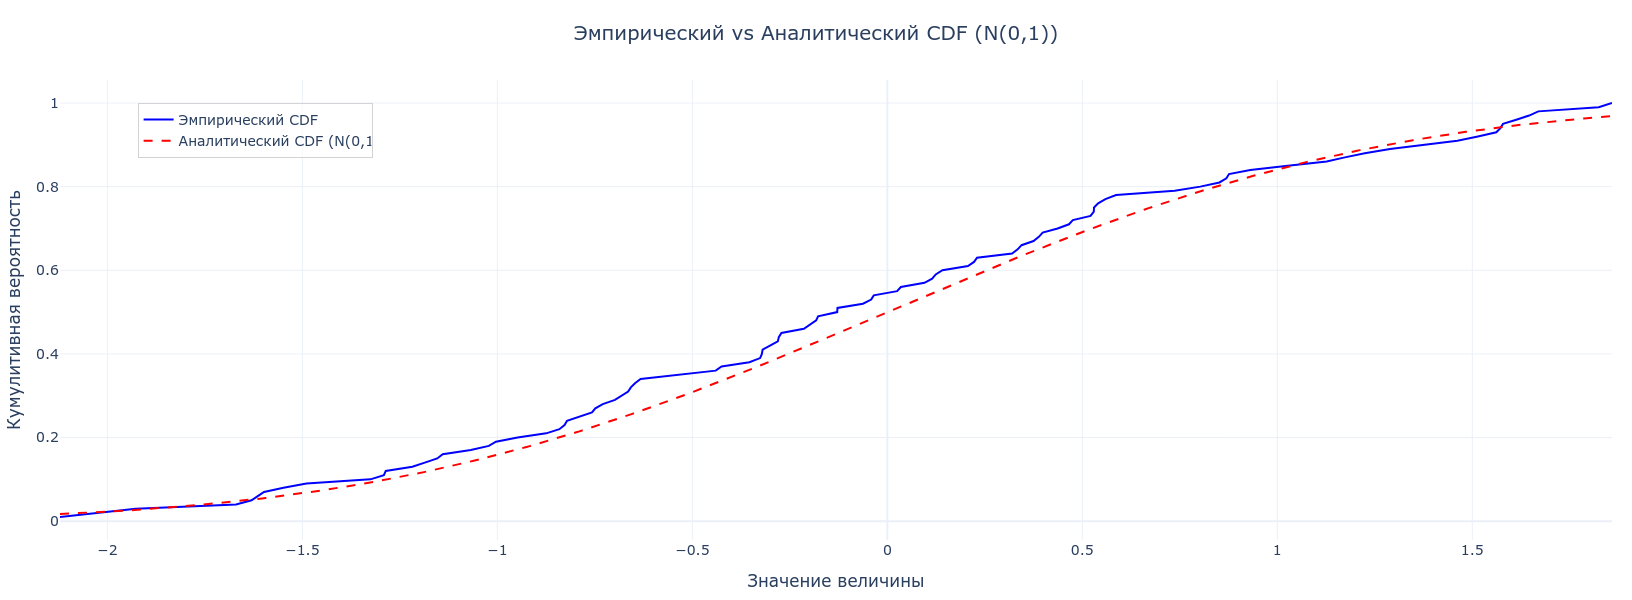

In [ ]:
import numpy as np
import plotly.graph_objects as go
from scipy.stats import norm

# 1. Generate random values (Normal distribution)
n_samples = 100
data = np.random.randn(n_samples)

# 2. Sort data and compute empirical CDF
sorted_data = np.sort(data)
empirical_cdf = np.arange(1, n_samples + 1) / n_samples

# 3. Analytical CDF (standard normal)
x_vals = np.linspace(sorted_data.min(), sorted_data.max(), 500)
analytical_cdf = norm.cdf(x_vals, loc=0, scale=1)

# 4. Create Plotly figure
fig = go.Figure()

# Empirical CDF
fig.add_trace(go.Scatter(
    x=sorted_data,
    y=empirical_cdf,
    mode='lines',
    name='Эмпирический CDF',
    line=dict(color='blue', width=2)
))

# Analytical CDF
fig.add_trace(go.Scatter(
    x=x_vals,
    y=analytical_cdf,
    mode='lines',
    name='Аналитический CDF (N(0,1))',
    line=dict(color='red', dash='dash', width=2)
))

# 5. Update layout
fig.update_layout(
    title=dict(
        text='Эмпирический vs аналитический CDF (N(0,1))',
        x=0.5,
        xanchor='center'
    ),
    xaxis_title='Значение величины',
    yaxis_title='Кумулятивная вероятность',
    width=600,
    height=600,
    template='plotly_white',
    font=dict(size=14),
    legend=dict(
        x=0.05, y=0.95,
        bgcolor='rgba(255,255,255,0.7)',
        bordercolor='lightgray',
        borderwidth=1
    ),
    margin=dict(l=60, r=20, t=80, b=60)
)

fig.show()

Если `CDF` для одного набора вариантов мажорирует (или совпадает) с `CDF` другого, то из этого следует, что его выбор параметров лучше (или безразличен).

Напомним, что общее пространство сетей предоставляет нам множество параметров: мы можем задать ширину блока (количество каналов) $c_0, c_1, c_2, c_3, c_4$, глубину (количество блоков) на этап $d_1, d_2, d_3, d_4$, коэффициенты `bottleneck` $k_1, k_2, k_3, k_4$ и ширину групп (количество групп) $g_1, g_2, g_3, g_4$.

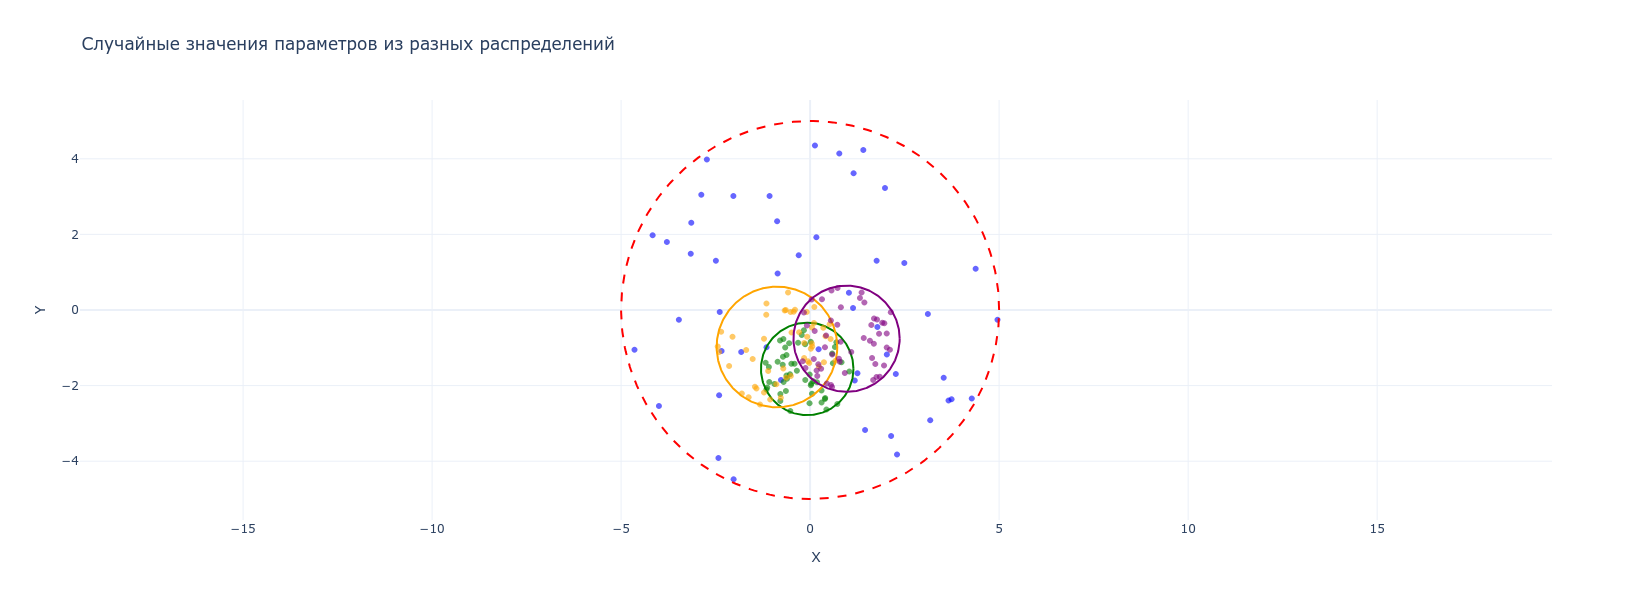

In [ ]:
import numpy as np
import plotly.graph_objects as go

# --- 1. Parameters ---
n_points = 50
base_center = (0, 0)
base_radius = 5

n_inner_circles = 3
inner_circle_max_radius = 2
points_per_inner_circle = 50

# --- 2. Generate points uniformly inside the base circle ---
r = base_radius * np.sqrt(np.random.rand(n_points))  # sqrt for uniform in circle
theta = 2 * np.pi * np.random.rand(n_points)
x_points = base_center[0] + r * np.cos(theta)
y_points = base_center[1] + r * np.sin(theta)

# --- 3. Generate inner circles inside the base circle ---
inner_circles = []
inner_points_all = []

for _ in range(n_inner_circles):
    # Random center inside base circle
    r_center = (base_radius - inner_circle_max_radius) * np.sqrt(np.random.rand())
    angle = 2 * np.pi * np.random.rand()
    cx = base_center[0] + r_center * np.cos(angle)
    cy = base_center[1] + r_center * np.sin(angle)

    # Random radius
    cr = np.random.uniform(0.5, inner_circle_max_radius)
    inner_circles.append((cx, cy, cr))

    # Generate points inside this inner circle
    r_inner = cr * np.sqrt(np.random.rand(points_per_inner_circle))
    theta_inner = 2 * np.pi * np.random.rand(points_per_inner_circle)
    x_inner = cx + r_inner * np.cos(theta_inner)
    y_inner = cy + r_inner * np.sin(theta_inner)
    inner_points_all.append((x_inner, y_inner))

# --- 4. Circle coordinates for plotting ---
theta_plot = np.linspace(0, 2*np.pi, 300)
base_circle_x = base_center[0] + base_radius * np.cos(theta_plot)
base_circle_y = base_center[1] + base_radius * np.sin(theta_plot)

# --- 5. Plotting ---
fig = go.Figure()

# Base circle points
fig.add_trace(go.Scatter(
    x=x_points, y=y_points,
    mode='markers',
    name='Base Circle Points',
    marker=dict(size=6, color='blue', opacity=0.6)
))

# Base circle outline
fig.add_trace(go.Scatter(
    x=base_circle_x, y=base_circle_y,
    mode='lines',
    name='Base Circle',
    line=dict(color='red', width=2, dash='dash')
))

# Inner circles and their points
colors = ['green', 'orange', 'purple']
for i, ((cx, cy, cr), color) in enumerate(zip(inner_circles, colors)):
    # Circle outline
    circle_x = cx + cr * np.cos(theta_plot)
    circle_y = cy + cr * np.sin(theta_plot)
    fig.add_trace(go.Scatter(
        x=circle_x, y=circle_y,
        mode='lines',
        name=f'Inner Circle {i+1}',
        line=dict(color=color, width=2)
    ))
    # Points inside inner circle
    x_inner, y_inner = inner_points_all[i]
    fig.add_trace(go.Scatter(
        x=x_inner, y=y_inner,
        mode='markers',
        name=f'Points Inner {i+1}',
        marker=dict(size=6, color=color, opacity=0.6)
    ))

# Layout
fig.update_layout(
    title='Случайные значения параметров из разных распределений',
    xaxis_title='X',
    yaxis_title='Y',
    width=600,
    height=600,
    template='plotly_white',
    yaxis=dict(scaleanchor="x", scaleratio=1),
    showlegend = False
)

fig.show()


Авторы подхода экспериментировали с общим коэффициентом `bottleneck` сети для всех её этапов $k_i = k$, что позволяет избавиться от трёх из четырёх параметров. Чтобы оценить, влияет ли это (негативно) на производительность, можно взять сети из ограниченного и неограниченного распределения и сравнить соответствующие `CDF`. Оказалось, что это ограничение вообще не влияет на точность распределения сетей, как видно на первом рисунке.

Аналогично, мы можем выбрать одинаковую ширину групп, встречающихся на разных этапах сети. И снова это не влияет на производительность, как видно на втором рисунке. Оба шага в совокупности уменьшают количество свободных параметров до 11.

<p style="text-align: center"><img src="...
AElFTkSuQmCC
" style="height:300px;"></p>

Мы ищем способы уменьшить множество потенциальных вариантов ширины и глубины ступеней. Разумно предположить, что по мере углубления количество каналов должно увеличиваться, то есть $c_i \leq c_{i+1} (w_i \leq w_{i+1})$. Точно так же разумно предположить, что по мере продвижения стадии должны становиться глубже (содержать большее количество блоков), то есть $d_i \leq d_{i+1}$. Это можно экспериментально проверить на третьем и четвёртом рисунке соответственно.

### RegNet

В результате получаемое пространство архитектур состоит из простых сетей, следующих легко интерпретируемым принципам проектирования:

- использовать одинаковое значение коэффициента «бутылочного горлышка» (bottleneck ratio) для всех стадий $k_i = k$;
- использовать одинаковую ширину групп (group width) для всех стадий $g_i = g$;
- увеличивать ширину сети от одной стадии к следующей                $c_i \leq c_{i+1} (w_i \leq w_{i+1})$;
- увеличивать глубину сети от одной стадии к следующей               $d_i \leq d_{i+1}$.

Анализ лучших сетей, полученных из распределения, показывает, что ширина сети в идеале возрастает линейно с индексом блока:

$$
w_i = w_0 + k \cdot i,
$$

где $i$ обозначает индекс блока, а $k$ — темп увеличения ширины. Поскольку на практике ширину можно изменять только между стадиями, получается кусочно-постоянная функция, специально сконструированная для аппроксимации такой линейной зависимости.

Кроме того, эксперименты показывают, что наилучшие результаты достигаются при коэффициенте бутылочного горлышка $b = 1$, то есть рекомендуется полностью отказаться от использования узких бутылочных блоков. Заинтересованным читателям предлагается ознакомиться с дополнительными подробностями проектирования конкретных сетей для различных уровней вычислительных затрат в работе [Radosavovic et al. (2020) — *Designing Network Design Spaces*](https://openaccess.thecvf.com/content_CVPR_2020/papers/Radosavovic_Designing_Network_Design_Spaces_CVPR_2020_paper.pdf).

Например, эффективный вариант `RegNetX` с 32 слоями реализуется без бутылочного горлышка ($b = 1$), при ширине группы $g = 16$, с числом каналов для первой и второй стадий 48 и 104 соответственно и глубиной этих стадий в 2 и 6 блоков. Примечательно, что описанные закономерности сохраняются даже при масштабировании сетей.

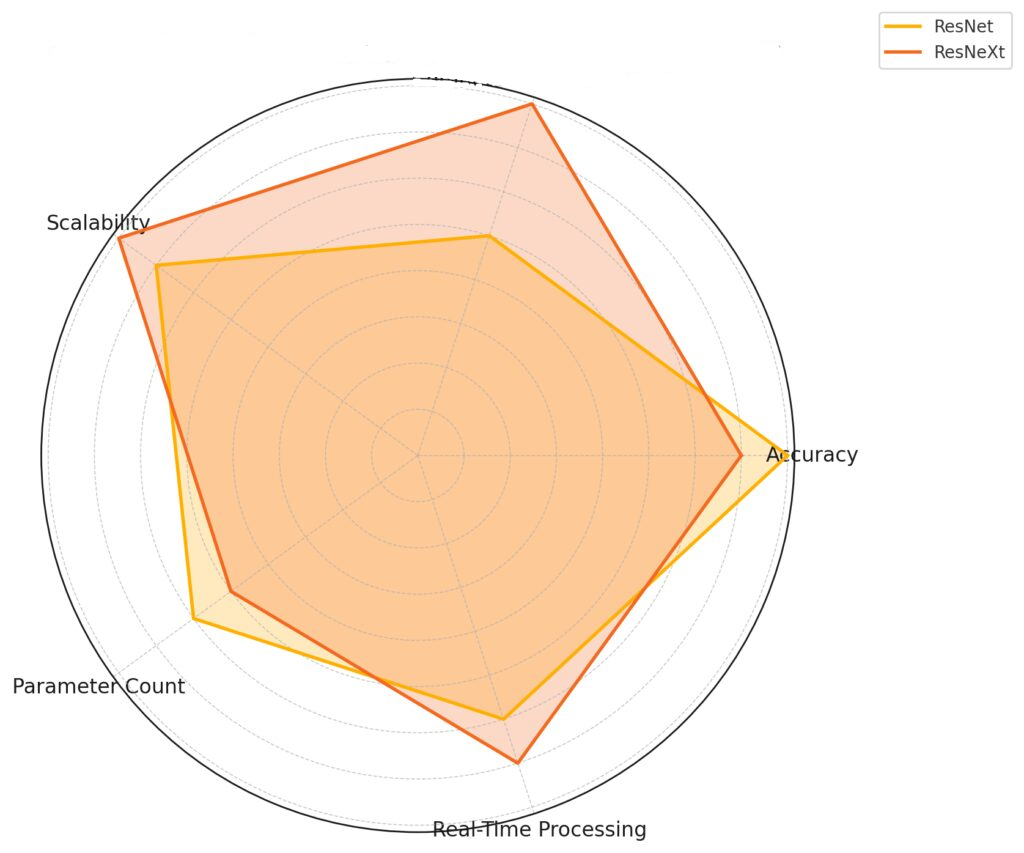

Обе архитектуры были широко приняты и протестированы на наборах данных `ImageNet` и `COCO`, среди прочих. Модели ResNeXt часто достигают аналогичной или более высокой
точности при выполнении задач классификации изображений по сравнению с `ResNet` той же глубины благодаря более высокой способности к обучению представлений.

Точность: `ResNeXt` обычно работает наравне или лучше с меньшим количеством параметров.
Эффективность: `ResNeXt` быстрее обучается для аналогичных уровней производительности, что делает её подходящей для приложений с ограниченными ресурсами.

Frame 2087329782.png